<a href="https://colab.research.google.com/github/leandrorechdev/Estimaciones-agricolas-de-Argentina-1969-2025/blob/main/Copia_de_COLAB_TPI_%C2%B7_Estimaciones_agr%C3%ADcolas_Argentina.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Estimaciones agrícolas de Argentina, 1969–2025
### Producción, territorio y rendimiento de los cultivos extensivos: limpieza, análisis exploratorio, visualización y modelos predictivos

https://hexagonx.io/tpi/

**Trabajo Práctico Integrador** · Introducción a la Ciencia de Datos · UGR Virtual · 2026
**Equipo:** Leandro Rech · Agustín Berardi · Lucas Cuneo · Ezequiel Cianchetta

---

**Cómo leer este notebook.** Está organizado en los cinco capítulos de la consigna. Cada sección abre con una explicación de *qué* se hace y *por qué*, sigue con el código y cierra con la lectura de los resultados. Las decisiones metodológicas importantes aparecen destacadas como notas. Para reproducirlo completo: **Entorno de ejecución → Ejecutar todo** (tarda unos 5 minutos; descarga los datos desde el repositorio público del proyecto).

| Capítulo | Contenido |
|:--|:--|
| **1. Definición y comprensión del problema** | Contexto, pregunta de investigación, ficha del dataset, diccionario de variables, alcance y roles |
| **2. Limpieza y procesamiento** | Normalización, duplicados, errores de escala, coherencia matemática, categorías superpuestas, variables derivadas |
| **3. Análisis exploratorio** | Estadística descriptiva, evolución, concentración, rendimiento ponderado, atípicos por cultivo, correlaciones |
| **4. Visualización** | Gráficos de síntesis y mapas de Argentina por provincia y departamento |
| **5. Modelos y ajustes** | Pronóstico de rendimiento, comparación de modelos, ajuste de hiperparámetros, interpretación y proyección 2025/26 |

# Capítulo 1 · Definición y comprensión del problema

## 1.1 Contexto

Argentina es uno de los principales productores y exportadores de granos del mundo, y el complejo agroindustrial explica una parte central de las divisas que ingresan al país. Esa producción, sin embargo, está **concentrada en pocos cultivos y en pocas provincias**, y su resultado depende fuertemente del **clima de cada campaña**: una sequía en la región pampeana se siente en toda la economía.

Entender *qué* se produce, *dónde* y *con qué productividad* es útil para planificar logística y acopio, diseñar seguros agrícolas, orientar políticas de transferencia tecnológica y anticipar el volumen de cosecha.

## 1.2 Pregunta de investigación

> **¿Cómo evolucionó la producción agrícola argentina desde 1969, dónde se concentra y en qué medida es posible anticipar el rendimiento de los cultivos a nivel departamental?**

**Objetivo general.** Construir una base limpia y trazable de las estimaciones agrícolas oficiales, describir sus patrones temporales y territoriales y evaluar modelos que estimen el rendimiento por departamento.

**Objetivos específicos.**

1. Depurar la base: detectar y corregir errores de carga, inconsistencias matemáticas y doble conteo, sin perder trazabilidad.
2. Caracterizar la evolución de la producción, la superficie y el rendimiento por cultivo y por territorio.
3. Medir la concentración productiva (por cultivo y por provincia) y la variabilidad del rendimiento.
4. Comparar modelos de predicción del rendimiento contra líneas de base simples y cuantificar cuánto se gana.
5. Dejar los resultados listos para un tablero interactivo (BI).

**Enfoque.** El trabajo combina tres miradas: **descriptiva** (qué pasó), **exploratoria** (qué relaciones aparecen entre variables y territorios) y **predictiva** (qué rendimiento cabe esperar).

## 1.3 Ficha del dataset

| Atributo | Detalle |
|:--|:--|
| **Nombre** | Estimaciones agrícolas |
| **Organismo** | Secretaría de Agricultura, Ganadería y Pesca de la Nación (Ministerio de Economía) |
| **Fuente** | Portal de datos abiertos [datos.gob.ar](https://datos.gob.ar) · copia versionada en el repositorio del proyecto en GitHub |
| **Alcance temporal** | Campañas 1969/70 a 2024/25 (56 campañas) |
| **Alcance geográfico** | 23 provincias y más de 500 departamentos (partidos) |
| **Unidad de análisis** | Una fila = un **cultivo** en un **departamento** durante una **campaña** |
| **Volumen** | 160.499 registros y 11 columnas en su versión cruda |
| **Contexto** | Económico-productivo: oferta agrícola, uso del suelo y productividad |

## 1.4 Diccionario de variables

| Variable | Tipo | Descripción |
|:--|:--|:--|
| `cultivo` | categórica | Cultivo estimado (soja, maíz, trigo, girasol, etc.). Incluye totales y subcategorías |
| `anio` | numérica | Primer año de la campaña (1969 corresponde a 1969/1970) |
| `campania` | texto | Campaña agrícola en formato `AAAA/AAAA` |
| `provincia`, `provincia_id` | categórica | Provincia y su código INDEC de 2 dígitos |
| `departamento`, `departamento_id` | categórica | Departamento o partido y su código INDEC de 5 dígitos |
| `superficie_sembrada_ha` | numérica | Hectáreas sembradas |
| `superficie_cosechada_ha` | numérica | Hectáreas efectivamente cosechadas |
| `produccion_tm` | numérica | Producción en toneladas |
| `rendimiento_kgxha` | numérica | Rendimiento en kilogramos por hectárea cosechada. **Variable objetivo del capítulo 5** |

Relación clave entre variables: **producción (t) ≈ superficie cosechada (ha) × rendimiento (kg/ha) ÷ 1000**. La usamos en el capítulo 2 para auditar la base.

## 1.5 Justificación de la elección

- **Relevancia:** el agro es el principal motor exportador del país; el tema tiene valor económico, social y de política pública.
- **Riqueza de variables:** combina dimensiones temporales, territoriales y de cultivo con tres métricas numéricas vinculadas entre sí, lo que permite análisis bivariados, controles de coherencia y modelos.
- **Escala y calidad:** es una fuente oficial, abierta y con más de medio siglo de historia a nivel departamental, muy por encima de los mínimos sugeridos (100 filas y 5 variables).
- **Variable objetivo natural:** el rendimiento es una medida de productividad que se puede modelar y comparar entre territorios.
- **Interés del equipo:** la temática es cercana a la región y a nuestras trayectorias, lo que facilita interpretar los resultados.

## 1.6 Alcance

Se trabaja con **todos los cultivos** para la parte descriptiva y con los **cuatro grandes cultivos extensivos** (soja, maíz, trigo y girasol) para los modelos, porque concentran la mayor parte de la superficie y tienen series departamentales largas. Quedan fuera del alcance las variables climáticas, de precios y de suelo, que no forman parte del dataset; se señalan como próximos pasos.

## 1.7 Roles en un proyecto como este

| Rol | Responsabilidad en este proyecto |
|:--|:--|
| **Analista de negocio** | Traduce necesidades del sector (productores, acopiadores, organismos públicos) en preguntas medibles y prioriza hallazgos |
| **Ingeniero/a de datos** | Diseña la ingesta reproducible, el pipeline de limpieza y la base que alimenta el tablero |
| **Analista de datos** | Audita la calidad, construye indicadores, realiza el EDA y las visualizaciones |
| **Científico/a de datos** | Diseña, valida e interpreta los modelos predictivos |
| **Consultor/a en datos** | Comunica resultados y recomendaciones a quienes toman decisiones |

## 1.8 Metodología

El trabajo sigue un ciclo inspirado en **CRISP-DM**: comprensión del problema y de los datos (cap. 1), preparación (cap. 2), exploración (caps. 3 y 4), modelado y evaluación (cap. 5). Cada transformación deja una marca en la base para que cualquier resultado pueda rastrearse hasta el dato original.

## 1.9 Preparación del entorno

Se importan las librerías y se define un **estilo gráfico único** para todo el notebook: una paleta fija por cultivo (soja siempre verde, maíz siempre amarillo, etc.), formato numérico argentino y funciones auxiliares que se reutilizan en los capítulos siguientes.

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 1.9  Librerías, estilo y funciones auxiliares
# ─────────────────────────────────────────────────────────────────────────────
import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}'.replace(',', 'X').replace('.', ',').replace('X', '.'))

# Paleta del proyecto: "de la paja al verde"
TINTA, GRIS, LINEA, FONDO = '#17231B', '#5A685D', '#D8DDD0', '#FFFFFF'
VERDE, DORADO, TIERRA, ALERTA = '#2F6B3A', '#C98A1B', '#7A4E2D', '#B23A2A'
RAMPA = ['#F4EDD3', '#E9D88F', '#C9B84F', '#8FA840', '#4E8B37', '#245E2C', '#123D1E']
from matplotlib.colors import LinearSegmentedColormap
CMAP_AGRO = LinearSegmentedColormap.from_list('agro', RAMPA)
CMAP_DIV = LinearSegmentedColormap.from_list('agro_div', ['#8C3B24', '#EBC08A', '#F2EEDC', '#A9CF8F', '#1C5228'])

# Color fijo por cultivo (el mismo que usa el tablero BI)
COLOR_CULTIVO = {
    'soja total': '#2E7D32', 'maíz': '#E0A400', 'trigo total': '#B5651D', 'girasol': '#F2C230',
    'sorgo': '#A23B2A', 'cebada total': '#8D9440', 'caña de azúcar': '#5B8DB8', 'avena': '#C9B27C',
    'maní': '#7E5A3C', 'algodón': '#9AA9B8', 'arroz': '#3E9C8F', 'papa total': '#8E6C8A',
    'naranja': '#F07F1A', 'limón': '#CFD82B', 'yerba mate': '#4F7942', 'poroto total': '#5C3A21',
}
NOMBRE = {'soja total': 'Soja', 'trigo total': 'Trigo', 'cebada total': 'Cebada', 'poroto total': 'Poroto',
          'papa total': 'Papa', 'cebolla total': 'Cebolla'}
nombre = lambda c: NOMBRE.get(c, str(c).capitalize())
color = lambda c: COLOR_CULTIVO.get(c, '#8A968C')

plt.rcParams.update({
    'figure.facecolor': FONDO, 'axes.facecolor': FONDO, 'savefig.facecolor': FONDO,
    'figure.dpi': 110, 'figure.figsize': (12, 5.5),
    'font.family': 'sans-serif', 'font.size': 11,
    'axes.edgecolor': LINEA, 'axes.labelcolor': GRIS, 'axes.titlesize': 15, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'axes.titlecolor': TINTA, 'axes.titlepad': 26,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': LINEA, 'grid.linestyle': '--', 'grid.alpha': .7,
    'xtick.color': GRIS, 'ytick.color': GRIS, 'legend.frameon': False,
})

def miles(x, d=0):
    """Formato argentino: 1.234.567,8"""
    return f'{x:,.{d}f}'.replace(',', 'X').replace('.', ',').replace('X', '.')

def toneladas(x):
    if abs(x) >= 1e6: return f'{miles(x / 1e6, 1)} M t'
    if abs(x) >= 1e3: return f'{miles(x / 1e3, 1)} mil t'
    return f'{miles(x)} t'

def eje_millones(ax, eje='y', sufijo='M'):
    f = mticker.FuncFormatter(lambda v, p: f'{miles(v / 1e6)}{sufijo}')
    (ax.yaxis if eje == 'y' else ax.xaxis).set_major_formatter(f)

def titulo(ax, t, sub=None):
    """Título a la izquierda con subtítulo gris debajo."""
    ax.set_title(t, pad=28 if sub else 12)
    if sub:
        ax.annotate(sub, xy=(0, 1), xycoords='axes fraction', xytext=(0, 7), textcoords='offset points',
                    color=GRIS, fontsize=10.5, va='bottom', ha='left')

def fuente(fig, txt='Fuente: Estimaciones agrícolas, SAGyP (datos.gob.ar). Elaboración propia.'):
    fig.text(0.01, -0.01, txt, color=GRIS, fontsize=8.5, ha='left', va='top')

def rendimiento_ponderado(d):
    """Rinde correcto de un agregado: Σ producción / Σ superficie cosechada (kg/ha).
    Solo usa filas con superficie cosechada > 0 para que numerador y denominador sean coherentes."""
    d = d[d['superficie_cosechada_ha'] > 0]
    s = d['superficie_cosechada_ha'].sum()
    return d['produccion_tm'].sum() * 1000 / s if s > 0 else np.nan

def nota(texto):
    display(Markdown(texto))

print('Entorno listo · pandas', pd.__version__, '· numpy', np.__version__)

Entorno listo · pandas 2.2.3 · numpy 2.1.3


## 1.10 Carga de los datos

Se lee el CSV crudo directamente desde el repositorio público del proyecto, de modo que el notebook sea reproducible en cualquier entorno. Los **códigos INDEC** (`provincia_id`, `departamento_id`) se leen como texto para conservar los ceros a la izquierda (`06` es Buenos Aires; leído como número sería `6`) y poder cruzarlos después con los mapas.

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 1.10  Carga del CSV crudo
# ─────────────────────────────────────────────────────────────────────────────
URL_CSV = ('https://raw.githubusercontent.com/leandrorechdev/proyecto_agro_ugr_2026_eda/'
           'refs/heads/main/estimaciones-agricolas-2026.csv')
RUTA_LOCAL = 'estimaciones-agricolas-2026.csv'

origen = RUTA_LOCAL if os.path.exists(RUTA_LOCAL) else URL_CSV
df_raw = pd.read_csv(origen, dtype={'provincia_id': str, 'departamento_id': str})
COLUMNAS_ORIGINALES = list(df_raw.columns)

print(f'Origen: {"archivo local" if origen == RUTA_LOCAL else "GitHub"}')
print(f'Dimensiones: {miles(df_raw.shape[0])} filas × {df_raw.shape[1]} columnas')
display(df_raw.head(5))

Origen: GitHub
Dimensiones: 160.499 filas × 11 columnas


,cultivo,anio,campania,provincia,provincia_id,departamento,departamento_id,superficie_sembrada_ha,superficie_cosechada_ha,produccion_tm,rendimiento_kgxha
0,ajo,1969,1969/1970,Buenos Aires,06,25 de Mayo,06854,3,3,10,3333
1,ajo,1969,1969/1970,Buenos Aires,06,Adolfo Gonzales Chaves,06014,15,15,82,5467
2,ajo,1969,1969/1970,Buenos Aires,06,Almirante Brown,06028,2,2,8,4000
3,ajo,1969,1969/1970,Buenos Aires,06,Balcarce,06063,450,450,2025,4500
4,ajo,1969,1969/1970,Buenos Aires,06,Cañuelas,06134,2,2,7,3500


## 1.11 Primera mirada: perfil de las variables

Antes de transformar nada, se revisa el tipo de cada columna, la cantidad de valores distintos, los nulos y un ejemplo. Es el "control de recepción" de la base.

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 1.11  Perfil de variables
# ─────────────────────────────────────────────────────────────────────────────
perfil = pd.DataFrame({
    'tipo': df_raw.dtypes.astype(str),
    'valores distintos': df_raw.nunique(dropna=False),
    'nulos': df_raw.isna().sum(),
    '% nulos': (df_raw.isna().mean() * 100).round(3),
    'ejemplo': [df_raw[c].dropna().iloc[0] for c in df_raw.columns],
})
display(perfil)

num = ['superficie_sembrada_ha', 'superficie_cosechada_ha', 'produccion_tm', 'rendimiento_kgxha']
print('\nResumen estadístico de las variables numéricas (base cruda):')
display(df_raw[num].describe(percentiles=[.25, .5, .75, .99]).T)

,tipo,valores distintos,nulos,% nulos,ejemplo
cultivo,object,41,0,"0,00",ajo
anio,int64,56,0,"0,00",1969
campania,object,56,0,"0,00",1969/1970
provincia,object,24,8,"0,01",Buenos Aires
provincia_id,object,24,8,"0,01",06
departamento,object,410,8,"0,01",25 de Mayo
departamento_id,object,508,8,"0,01",06854
superficie_sembrada_ha,int64,10090,0,"0,00",3
superficie_cosechada_ha,int64,12130,0,"0,00",3
produccion_tm,int64,23770,0,"0,00",10



Resumen estadístico de las variables numéricas (base cruda):


,count,mean,std,min,25%,50%,75%,99%,max
superficie_sembrada_ha,"160.499,00","12.565,28","36.260,60","0,00","200,00","1.500,00","9.000,00","170.258,92","894.613,00"
superficie_cosechada_ha,"160.499,00","11.022,88","34.774,17","0,00","74,00","800,00","6.275,00","163.400,00","883.613,00"
produccion_tm,"160.499,00","34.385,99","130.061,58","0,00","197,00","1.820,00","14.800,00","576.303,40","8.620.000,00"
rendimiento_kgxha,"160.499,00","3.457,05","5.475,85","0,00","1.000,00","2.000,00","3.500,00","26.453,22","300.000,00"


**Lectura.** La base llega prácticamente completa: solo 8 filas no tienen provincia ni departamento (0,005 %). El resumen numérico ya anticipa el problema principal que trata el capítulo 2: el **máximo del rendimiento** está muy por encima del percentil 99, lo que sugiere errores de carga (ceros de más). También se observa que conviven `soja total` con `soja 1ra` y `soja 2da`: si se sumaran todas, la soja se contaría dos veces.

# Capítulo 2 · Limpieza y procesamiento de los datos

El objetivo de este capítulo es pasar de la base cruda a un **dataset de análisis confiable** sin borrar información en silencio. La regla que seguimos en todo el pipeline es simple:

> **Nota metodológica.** Ningún dato se modifica sin dejar rastro. Cuando se corrige un valor se guarda el original en una columna `_original`; cuando un registro es dudoso pero plausible, no se elimina: se marca con una bandera (`flag_…`) para poder filtrarlo o auditarlo después.

| Paso | Control | Tratamiento |
|:--:|:--|:--|
| 2.1 | Formato de textos y tipos numéricos | Normalización |
| 2.2 | Duplicados exactos y por clave | Eliminación / verificación |
| 2.3 | Categorías superpuestas (totales vs. subcategorías) | Diagnóstico |
| 2.4 | Rendimientos imposibles | Auditoría |
| 2.5 | Errores de escala (ceros de más) | Corrección ÷10 con umbrales por cultivo |
| 2.6 | Producción ≠ superficie × rendimiento | Recálculo selectivo |
| 2.7 | Superficie cosechada > sembrada | Bandera |
| 2.8 | Doble conteo | Exclusión de subcategorías |
| 2.9 | Variables derivadas | Región, grupo de cultivo, ratio de cosecha |

## 2.1 Normalización de textos y tipos

Se pasan los textos a minúsculas y sin espacios sobrantes para que `" Maíz"` y `"maíz"` no cuenten como cultivos distintos, **preservando los nulos reales** (convertir con `astype(str)` los transformaría en la palabra `"nan"`). Las métricas se convierten a número con un control que detiene la ejecución si aparece algún valor no numérico. Las 8 filas sin ubicación no se borran: se marcan en `geo_nula` para que su producción siga contando en los totales nacionales.

Se guardan además los nombres originales de provincia y departamento (con mayúsculas y tildes) para usarlos en tablas y gráficos.

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 2.1  Normalización
# ─────────────────────────────────────────────────────────────────────────────
est = df_raw.copy()
est['provincia_nombre'] = est['provincia'].str.strip()
est['departamento_nombre'] = est['departamento'].str.strip()

for col in ['cultivo', 'provincia', 'departamento', 'campania']:
    est[col] = est[col].str.strip().str.lower()

nulos_antes = est[num].isna().sum().sum()
for col in num:
    est[col] = pd.to_numeric(est[col], errors='coerce').astype('float64')
assert est[num].isna().sum().sum() == nulos_antes, 'La conversión numérica generó nulos nuevos'

est['geo_nula'] = est[['provincia', 'departamento']].isna().any(axis=1)

print(f'Cultivos distintos: {df_raw["cultivo"].nunique()} antes → {est["cultivo"].nunique()} después de normalizar')
print(f'Filas sin ubicación marcadas en geo_nula: {int(est["geo_nula"].sum())}')
print(f'Nulos en métricas numéricas: {int(est[num].isna().sum().sum())}')

Cultivos distintos: 41 antes → 41 después de normalizar
Filas sin ubicación marcadas en geo_nula: 8
Nulos en métricas numéricas: 0


## 2.2 Duplicados

Se controlan dos niveles:

1. **Duplicados exactos**: filas idénticas en las 11 columnas originales. Se eliminan.
2. **Duplicados por clave**: más de una fila para el mismo `cultivo + departamento + campaña`, aunque los valores difieran. Es el control más exigente, porque un duplicado con números distintos no se detecta comparando filas completas.

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 2.2  Duplicados exactos y por clave lógica
# ─────────────────────────────────────────────────────────────────────────────
n_dup = int(est.duplicated(subset=COLUMNAS_ORIGINALES).sum())
est = est.drop_duplicates(subset=COLUMNAS_ORIGINALES).reset_index(drop=True)

CLAVE = ['cultivo', 'departamento_id', 'campania']
con_ubicacion = est[est['departamento_id'].notna() & ~est['departamento_id'].str.endswith('000', na=False)]
dup_clave = con_ubicacion[con_ubicacion.duplicated(subset=CLAVE, keep=False)]

print(f'Duplicados exactos eliminados: {n_dup}')
print(f'Registros que comparten clave cultivo + departamento + campaña: {len(dup_clave)}')
if len(dup_clave):
    display(dup_clave.sort_values(CLAVE).head(10))

Duplicados exactos eliminados: 0
Registros que comparten clave cultivo + departamento + campaña: 0


**Lectura.** No hay duplicados exactos ni por clave en los departamentos identificados: cada cultivo tiene a lo sumo una estimación por departamento y campaña. Los registros con código terminado en `000` corresponden a departamentos **"sin definir"** (producción informada a nivel provincial) y se excluyen de este control porque pueden repetirse legítimamente.

## 2.3 Categorías superpuestas: totales y subcategorías

El dataset informa algunos cultivos **dos veces**: como total y desagregado. Por ejemplo, `soja total` convive con `soja 1ra` y `soja 2da`. Si se suman todas las filas de soja, la producción se duplica. Antes de resolverlo (paso 2.8) se dimensiona el problema.

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 2.3  Diagnóstico de familias de cultivos
# ─────────────────────────────────────────────────────────────────────────────
FAMILIAS = {
    'Soja':   ('soja total',   ['soja 1ra', 'soja 2da']),
    'Trigo':  ('trigo total',  ['trigo candeal', 'trigo pan']),
    'Cebada': ('cebada total', ['cebada cervecera', 'cebada forrajera']),
    'Poroto': ('poroto total', ['poroto negro', 'poroto alubia', 'poroto otros']),
}
HIJOS = [h for _, hs in FAMILIAS.values() for h in hs]

filas = []
for fam, (padre, hijos) in FAMILIAS.items():
    p = est[est['cultivo'] == padre]
    h = est[est['cultivo'].isin(hijos)]
    filas.append({'familia': fam, 'total (padre)': padre, 'subcategorías (hijos)': ' + '.join(hijos),
                  'campañas padre': f'{p["anio"].min()}–{p["anio"].max()}',
                  'campañas hijos': f'{h["anio"].min()}–{h["anio"].max()}' if len(h) else '–',
                  'filas hijos': len(h)})
display(pd.DataFrame(filas).set_index('familia'))

,total (padre),subcategorías (hijos),campañas padre,campañas hijos,filas hijos
familia,,,,,
Soja,soja total,soja 1ra + soja 2da,1969–2024,2000–2024,11585
Trigo,trigo total,trigo candeal + trigo pan,1969–2024,1976–2024,1245
Cebada,cebada total,cebada cervecera + cebada forrajera,2016–2024,1969–2015,10997
Poroto,poroto total,poroto negro + poroto alubia + poroto otros,1969–2024,2021–2024,397


**Lectura.** Los totales cubren toda la serie histórica, mientras que las subcategorías se informan solo en las campañas más recientes. Por eso la decisión correcta es **conservar los totales y excluir las subcategorías**: así no se pierde historia y no hay doble conteo.

## 2.4 Auditoría de rendimientos imposibles

Ningún cultivo extensivo rinde 50.000 kg/ha. Se buscan los registros con rendimiento por encima de umbrales agronómicos razonables. El umbral general es **15.000 kg/ha**; cultivos de alto tonelaje (caña de azúcar, cítricos, papa, cebolla, banana, yerba mate, té y ajo) tienen umbrales propios, porque para ellos esos valores sí son normales.

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 2.4  Rendimientos por encima del umbral agronómico
# ─────────────────────────────────────────────────────────────────────────────
UMBRAL_DEFECTO = 15_000
UMBRALES_CULTIVO = {
    'caña de azúcar': 150_000, 'banana': 60_000, 'papa total': 60_000, 'cebolla total': 70_000,
    'naranja': 60_000, 'mandarina': 60_000, 'limón': 80_000, 'pomelo': 80_000,
    'yerba mate': 25_000, 'té': 20_000, 'ajo': 20_000,
}
umbral = est['cultivo'].map(UMBRALES_CULTIVO).fillna(UMBRAL_DEFECTO)
sospechosos = est[est['rendimiento_kgxha'] > umbral]

print(f'Registros por encima del umbral de su cultivo: {len(sospechosos)}')
display(sospechosos[['cultivo', 'campania', 'provincia_nombre', 'departamento_nombre',
                     'superficie_cosechada_ha', 'produccion_tm', 'rendimiento_kgxha']])

Registros por encima del umbral de su cultivo: 4


,cultivo,campania,provincia_nombre,departamento_nombre,superficie_cosechada_ha,produccion_tm,rendimiento_kgxha
43727,cebolla total,1996/1997,Salta,Rosario de la Frontera,"3,00","900,00","300.000,00"
77933,maíz,1994/1995,Tucumán,Famaillá,"300,00","10.000,00","33.333,00"
121801,soja total,1985/1986,Santa Fe,Vera,"10.000,00","200.000,00","20.000,00"
127475,soja total,2011/2012,Córdoba,San Alberto,"112,00","2.229,00","19.902,00"


## 2.5 Corrección de errores de escala

Los valores detectados tienen la forma típica de un **error de tipeo de ceros**: el rinde es exactamente 10, 100 o 1000 veces un valor plausible. Se corrigen dividiendo por 10 (hasta tres veces) hasta quedar bajo el umbral, se guarda el factor aplicado y se recalcula la producción con la superficie cosechada.

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 2.5  Corrección ÷10 con trazabilidad
# ─────────────────────────────────────────────────────────────────────────────
est['rendimiento_original'] = est['rendimiento_kgxha']
est['produccion_original'] = est['produccion_tm']
est['factor_correccion'] = 1

for _ in range(3):
    m = est['rendimiento_kgxha'] > umbral
    if not m.any():
        break
    est.loc[m, 'rendimiento_kgxha'] /= 10
    est.loc[m, 'factor_correccion'] *= 10

corregidos = est['factor_correccion'] > 1
recalc = corregidos & (est['superficie_cosechada_ha'] > 0)
est.loc[recalc, 'produccion_tm'] = est.loc[recalc, 'superficie_cosechada_ha'] * est.loc[recalc, 'rendimiento_kgxha'] / 1000

print(f'Registros corregidos: {int(corregidos.sum())} · con producción recalculada: {int(recalc.sum())}')
print(f'Registros que siguen sobre el umbral: {int((est["rendimiento_kgxha"] > umbral).sum())}')
display(est.loc[corregidos, ['cultivo', 'campania', 'departamento_nombre', 'rendimiento_original',
                             'rendimiento_kgxha', 'produccion_original', 'produccion_tm', 'factor_correccion']])

Registros corregidos: 4 · con producción recalculada: 4
Registros que siguen sobre el umbral: 0


,cultivo,campania,departamento_nombre,rendimiento_original,rendimiento_kgxha,produccion_original,produccion_tm,factor_correccion
43727,cebolla total,1996/1997,Rosario de la Frontera,"300.000,00","30.000,00","900,00","90,00",10
77933,maíz,1994/1995,Famaillá,"33.333,00","3.333,30","10.000,00","999,99",10
121801,soja total,1985/1986,Vera,"20.000,00","2.000,00","200.000,00","20.000,00",10
127475,soja total,2011/2012,San Alberto,"19.902,00","1.990,20","2.229,00","222,90",10


## 2.6 Coherencia matemática: producción = superficie cosechada × rendimiento

Se compara la producción informada con la que surge de la fórmula. Como el rendimiento se publica **redondeado a kilos enteros**, es esperable una pequeña diferencia: el error máximo por redondeo es `superficie × 0,5 kg ÷ 1000` toneladas. Solo se recalculan las diferencias que **superan esa cota** y que tienen superficie cosechada para hacer la cuenta.

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 2.6  Coherencia con tolerancia de redondeo
# ─────────────────────────────────────────────────────────────────────────────
est['produccion_esperada_tm'] = est['superficie_cosechada_ha'] * est['rendimiento_kgxha'] / 1000
dif = (est['produccion_tm'] - est['produccion_esperada_tm']).abs()
mayor_1t = dif > 1
fuera_cota = dif > est['superficie_cosechada_ha'] * 0.0005 + 0.5
sin_cosecha = mayor_1t & (est['superficie_cosechada_ha'] == 0)

est['flag_prod_recalculada'] = mayor_1t & fuera_cota & (est['superficie_cosechada_ha'] > 0)
est.loc[est['flag_prod_recalculada'], 'produccion_tm'] = est.loc[est['flag_prod_recalculada'], 'produccion_esperada_tm']

resumen_coherencia = pd.Series({
    'Diferencias mayores a 1 t': int(mayor_1t.sum()),
    '… explicadas por el redondeo del rinde': int((mayor_1t & ~fuera_cota).sum()),
    '… con producción pero sin superficie cosechada (se conservan)': int(sin_cosecha.sum()),
    '… inconsistencias reales recalculadas': int(est['flag_prod_recalculada'].sum()),
}, name='registros')
display(resumen_coherencia.to_frame())
display(est.loc[est['flag_prod_recalculada'], ['cultivo', 'campania', 'departamento_nombre', 'superficie_cosechada_ha',
                                               'rendimiento_kgxha', 'produccion_original', 'produccion_tm']].head(8))

,registros
Diferencias mayores a 1 t,20040
… explicadas por el redondeo del rinde,16824
… con producción pero sin superficie cosechada (se conservan),3201
… inconsistencias reales recalculadas,15


,cultivo,campania,departamento_nombre,superficie_cosechada_ha,rendimiento_kgxha,produccion_original,produccion_tm
61295,girasol,2019/2020,Brandsen,"718,00","2.201,00","1.579,00","1.580,32"
61315,girasol,2019/2020,General Paz,"718,00","2.201,00","1.579,00","1.580,32"
61332,girasol,2019/2020,Marcos Paz,"431,00","2.200,00","947,00","948,20"
86410,maíz,2024/2025,Bermejo,"114,00","3.800,00","431,00","433,20"
86412,maíz,2024/2025,Laishí,"859,00","3.800,00","3.266,00","3.264,20"
86434,maíz,2024/2025,Dr. Manuel Belgrano,"100,00","4.000,00","398,00","400,00"
86437,maíz,2024/2025,Palpalá,"139,00","4.000,00","554,00","556,00"
86463,maíz,2024/2025,Concepción,"85,00","5.000,00","423,00","425,00"


**Lectura.** De las más de 20.000 diferencias, la gran mayoría se explica por el redondeo y no requiere acción. Hay unos 3.200 registros con producción pero sin superficie cosechada: corresponden a cultivos en los que la fuente no informa la cosecha (por ejemplo, forrajeras o cultivos perennes en algunos años). No se pueden recalcular, así que se conservan como están. Solo **15 registros** eran inconsistencias reales y se corrigieron.

## 2.7 Superficie cosechada mayor que la sembrada

Cosechar más de lo que se sembró es físicamente imposible. Estos casos son pocos y pueden deberse a reajustes de la fuente entre estimaciones; se **marcan** sin eliminarlos.

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 2.7  Bandera de cosechada > sembrada
# ─────────────────────────────────────────────────────────────────────────────
est['flag_cosechada_mayor_sembrada'] = est['superficie_cosechada_ha'] > est['superficie_sembrada_ha']
casos = est[est['flag_cosechada_mayor_sembrada']]
print(f'Registros marcados: {len(casos)} · cultivos: {", ".join(sorted(casos["cultivo"].unique()))}')
display(casos[['cultivo', 'campania', 'departamento_nombre', 'superficie_sembrada_ha', 'superficie_cosechada_ha']])

Registros marcados: 11 · cultivos: soja 1ra, soja 2da


,cultivo,campania,departamento_nombre,superficie_sembrada_ha,superficie_cosechada_ha
110094,soja 1ra,2010/2011,Fray Justo Santa María de Oro,"10.225,00","10.349,00"
110740,soja 1ra,2012/2013,Rosario,"33.100,00","35.100,00"
111169,soja 1ra,2014/2015,Santa Rosa,"9.000,00","16.130,00"
111170,soja 1ra,2014/2015,El Alto,"2.200,00","2.300,00"
111224,soja 1ra,2014/2015,Palpalá,"10,00","40,00"
111226,soja 1ra,2014/2015,Ledesma,"70,00","85,00"
111229,soja 1ra,2014/2015,El Carmen,"0,00","120,00"
111234,soja 1ra,2014/2015,San Antonio,"855,00","875,00"
111235,soja 1ra,2014/2015,Santa Bárbara,"3.350,00","3.950,00"
111428,soja 1ra,2015/2016,Santa Rosa,"17.322,00","17.422,00"


**Lectura.** Todos los casos pertenecen a subcategorías de soja (primera y segunda), que se excluyen en el paso siguiente. En el dataset de análisis no queda ningún registro con este problema, pero la bandera se conserva por trazabilidad.

## 2.8 Resolución del doble conteo

Siguiendo el diagnóstico del paso 2.3, se construye el dataset de análisis **conservando los totales** (`soja total`, `trigo total`, `cebada total`, `poroto total`) y **excluyendo sus subcategorías**. Esta exclusión es la única razón por la que la base pasa de 160.499 a 136.275 filas: no se pierde información, solo se elimina la duplicación.

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 2.8  Dataset de análisis sin doble conteo
# ─────────────────────────────────────────────────────────────────────────────
prod_bruta = est['produccion_tm'].sum()
df = est[~est['cultivo'].isin(HIJOS)].copy().reset_index(drop=True)

print(f'Filas: {miles(len(est))} → {miles(len(df))}  (se excluyen {miles(len(est) - len(df))} filas de subcategorías)')
print(f'Producción acumulada: {toneladas(prod_bruta)} con doble conteo → {toneladas(df["produccion_tm"].sum())} sin doble conteo')
print(f'Sobreestimación evitada: {toneladas(prod_bruta - df["produccion_tm"].sum())}')

Filas: 160.499 → 136.275  (se excluyen 24.224 filas de subcategorías)
Producción acumulada: 5.518,7 M t con doble conteo → 4.355,2 M t sin doble conteo
Sobreestimación evitada: 1.163,6 M t


## 2.9 Variables derivadas

Se agregan variables que facilitan el análisis y el modelado:

- **`region`**: región agroeconómica según el código de provincia (Pampeana, NOA, NEA, Cuyo, Patagonia).
- **`grupo`**: familia del cultivo (cereales, oleaginosas, industriales, frutales, hortalizas, legumbres).
- **`ratio_cosecha`**: proporción de la superficie sembrada que se cosechó, un indicador indirecto de pérdidas (sequías, heladas, anegamientos) o de destino forrajero.
- **`anio`** como entero, para ordenar y modelar la tendencia temporal.

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 2.9  Variables derivadas
# ─────────────────────────────────────────────────────────────────────────────
REGIONES = {'Pampeana': ['06', '14', '82', '30', '42'], 'NOA': ['38', '66', '90', '86', '10'],
            'NEA': ['22', '34', '18', '54'], 'Cuyo': ['50', '70', '74', '46'], 'Patagonia': ['58', '62', '26', '78', '94']}
GRUPOS = {
    'Cereales': ['maíz', 'trigo total', 'sorgo', 'avena', 'centeno', 'cebada total', 'arroz', 'mijo', 'alpiste'],
    'Oleaginosas': ['soja total', 'girasol', 'maní', 'lino', 'colza', 'cártamo', 'jojoba', 'tung'],
    'Industriales': ['algodón', 'caña de azúcar', 'yerba mate', 'té'],
    'Frutales': ['naranja', 'mandarina', 'limón', 'pomelo', 'banana'],
    'Hortalizas': ['papa total', 'cebolla total', 'ajo'],
    'Legumbres': ['poroto total', 'arveja', 'garbanzo', 'lenteja'],
}
prov_region = {p: r for r, ps in REGIONES.items() for p in ps}
cult_grupo = {c: g for g, cs in GRUPOS.items() for c in cs}

df['anio'] = df['anio'].astype(int)
df['region'] = df['provincia_id'].map(prov_region)
df['grupo'] = df['cultivo'].map(cult_grupo).fillna('Otros')
df['ratio_cosecha'] = np.where(df['superficie_sembrada_ha'] > 0,
                               df['superficie_cosechada_ha'] / df['superficie_sembrada_ha'], np.nan)

display(df.groupby('grupo').agg(cultivos=('cultivo', 'nunique'), registros=('cultivo', 'size'),
                                produccion_tm=('produccion_tm', 'sum')).sort_values('produccion_tm', ascending=False))

,cultivos,registros,produccion_tm
grupo,,,
Cereales,9,69086,"2.149.791.575,39"
Oleaginosas,8,31454,"1.548.774.966,46"
Industriales,4,7650,"514.230.345,00"
Hortalizas,3,14135,"72.632.488,00"
Frutales,5,10185,"51.029.609,00"
Legumbres,4,3765,"18.709.647,00"


## 2.10 Resumen del pipeline de calidad

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 2.10  Resumen del pipeline y exportación del dataset limpio
# ─────────────────────────────────────────────────────────────────────────────
resumen = pd.DataFrame([
    ('Filas crudas', len(df_raw), 'Base original de datos.gob.ar'),
    ('Duplicados exactos', n_dup, 'Eliminados'),
    ('Filas sin ubicación', int(est['geo_nula'].sum()), 'Marcadas en geo_nula; cuentan en totales'),
    ('Rendimientos con error de escala', int(corregidos.sum()), 'Corregidos ÷10; original en rendimiento_original'),
    ('Producciones inconsistentes', int(est['flag_prod_recalculada'].sum()), 'Recalculadas; marcadas en flag_prod_recalculada'),
    ('Cosechada mayor que sembrada', int(est['flag_cosechada_mayor_sembrada'].sum()), 'Marcadas en flag_cosechada_mayor_sembrada'),
    ('Filas de subcategorías', len(est) - len(df), 'Excluidas para evitar doble conteo'),
    ('Filas del dataset de análisis', len(df), f'{df["cultivo"].nunique()} cultivos · {df["campania"].nunique()} campañas'),
], columns=['control', 'registros', 'tratamiento']).set_index('control')
display(resumen)

ARCHIVO_LIMPIO = 'ESTIMACIONES_AGRICOLAS_LIMPIA_EDA.csv'
df.to_csv(ARCHIVO_LIMPIO, index=False, encoding='utf-8-sig')
print(f'\nDataset limpio exportado: {ARCHIVO_LIMPIO} ({miles(len(df))} filas × {df.shape[1]} columnas)')
print('Este archivo es el que se importa en el tablero BI.')

,registros,tratamiento
control,,
Filas crudas,160499,Base original de datos.gob.ar
Duplicados exactos,0,Eliminados
Filas sin ubicación,8,Marcadas en geo_nula; cuentan en totales
Rendimientos con error de escala,4,Corregidos ÷10; original en rendimiento_original
Producciones inconsistentes,15,Recalculadas; marcadas en flag_prod_recalculada
Cosechada mayor que sembrada,11,Marcadas en flag_cosechada_mayor_sembrada
Filas de subcategorías,24224,Excluidas para evitar doble conteo
Filas del dataset de análisis,136275,33 cultivos · 56 campañas



Dataset limpio exportado: ESTIMACIONES_AGRICOLAS_LIMPIA_EDA.csv (136.275 filas × 23 columnas)
Este archivo es el que se importa en el tablero BI.


# Capítulo 3 · Análisis exploratorio de los datos

Con la base depurada, el análisis exploratorio busca responder las preguntas descriptivas del capítulo 1: qué se produce, dónde, cómo cambió y qué tan variable es el rendimiento.

> **Nota metodológica: rendimiento ponderado.** El rendimiento de un conjunto de registros **no** es el promedio simple de los rendimientos de cada fila. Un departamento de 500 ha pesaría lo mismo que uno de 500.000 ha. El rinde correcto de un agregado es **Σ producción ÷ Σ superficie cosechada**, y solo tiene sentido **dentro de un mismo cultivo**: promediar soja (≈ 2.800 kg/ha) con caña de azúcar (≈ 60.000 kg/ha) no describe a ninguno de los dos. Todo el capítulo usa la función `rendimiento_ponderado`.

## 3.1 Panorama general

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 3.1  Indicadores generales
# ─────────────────────────────────────────────────────────────────────────────
ANIO_MIN, ANIO_MAX = df['anio'].min(), df['anio'].max()
kpi = pd.Series({
    'Campañas': f'{ANIO_MIN}/{ANIO_MIN + 1} a {ANIO_MAX}/{ANIO_MAX + 1} ({df["campania"].nunique()})',
    'Cultivos': df['cultivo'].nunique(),
    'Provincias': df['provincia_id'].nunique(),
    'Departamentos': df['departamento_id'].nunique(),
    'Producción acumulada': toneladas(df['produccion_tm'].sum()),
    'Superficie sembrada acumulada': f'{miles(df["superficie_sembrada_ha"].sum() / 1e6, 1)} M ha',
    'Producción promedio por campaña': toneladas(df.groupby('anio')['produccion_tm'].sum().mean()),
    'Superficie sembrada no cosechada': f'{miles((1 - df["superficie_cosechada_ha"].sum() / df["superficie_sembrada_ha"].sum()) * 100, 1)} %',
}, name='valor')
display(kpi.to_frame())

,valor
Campañas,1969/1970 a 2024/2025 (56)
Cultivos,33
Provincias,23
Departamentos,506
Producción acumulada,"4.355,2 M t"
Superficie sembrada acumulada,"1.564,9 M ha"
Producción promedio por campaña,"77,8 M t"
Superficie sembrada no cosechada,"14,5 %"


## 3.2 Estadística descriptiva por cultivo

Para los diez cultivos de mayor volumen se calcula la producción acumulada, la superficie, el rendimiento ponderado y su **coeficiente de variación interanual** (cuánto oscila el rinde nacional de una campaña a otra, en % de su media).

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 3.2  Descriptiva por cultivo
# ─────────────────────────────────────────────────────────────────────────────
def serie_rinde(d):
    """Rinde ponderado nacional por campaña."""
    c = d[d['superficie_cosechada_ha'] > 0].groupby('anio')[['produccion_tm', 'superficie_cosechada_ha']].sum()
    return c['produccion_tm'] * 1000 / c['superficie_cosechada_ha']

top10 = df.groupby('cultivo')['produccion_tm'].sum().nlargest(10).index
filas = []
for c in top10:
    d = df[df['cultivo'] == c]
    r = serie_rinde(d)
    filas.append({'cultivo': nombre(c),
                  'producción acumulada (M t)': d['produccion_tm'].sum() / 1e6,
                  'participación %': d['produccion_tm'].sum() / df['produccion_tm'].sum() * 100,
                  'sup. sembrada (M ha)': d['superficie_sembrada_ha'].sum() / 1e6,
                  'rinde ponderado (kg/ha)': rendimiento_ponderado(d),
                  'rinde últimas 5 campañas': rendimiento_ponderado(d[d['anio'] > ANIO_MAX - 5]),
                  'CV interanual del rinde %': r.std() / r.mean() * 100,
                  'campañas': d['anio'].nunique()})
desc = pd.DataFrame(filas).set_index('cultivo')
display(desc.style.format('{:,.1f}', subset=desc.columns[:-1]).format('{:,.0f}', subset=['rinde ponderado (kg/ha)', 'rinde últimas 5 campañas'])
        .background_gradient(cmap=CMAP_AGRO, subset=['participación %']))

,producción acumulada (M t),participación %,sup. sembrada (M ha),rinde ponderado (kg/ha),rinde últimas 5 campañas,CV interanual del rinde %,campañas
cultivo,,,,,,,
Soja,"1,322.0",30.4,523.6,"2,602","2,663",23.3,56
Maíz,"1,148.4",26.4,264.1,"5,408","6,561",36.7,56
Trigo,671.7,15.4,313.9,"2,274","2,857",26.5,56
Caña de azúcar,440.3,10.1,10.2,"49,864",nan,12.1,31
Sorgo,200.9,4.6,74.8,"3,354","4,008",24.6,56
Girasol,177.8,4.1,117.4,"1,586","2,121",31.1,56
Papa,59.0,1.4,3.4,"18,079",nan,27.2,29
Arroz,48.1,1.1,9.0,"5,572","6,841",26.3,56
Cebada,39.2,0.9,12.5,"3,718","3,658",10.1,9


**Lectura.** Tres cultivos (soja, maíz y trigo) explican cerca de tres cuartos del volumen histórico. El rinde reciente es claramente superior al promedio histórico en todos los granos, reflejo del cambio tecnológico (genética, siembra directa, fertilización). La caña de azúcar aparece entre los grandes por **tonelaje**, pero ocupa poca superficie: por eso conviene leer la producción en toneladas junto con la superficie.

## 3.3 Evolución temporal de la producción

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 3.3  Evolución, crecimiento y campañas críticas
# ─────────────────────────────────────────────────────────────────────────────
anual = df.groupby('anio').agg(produccion_tm=('produccion_tm', 'sum'),
                               sup_sembrada=('superficie_sembrada_ha', 'sum'),
                               registros=('cultivo', 'size'))
anual['var_%'] = anual['produccion_tm'].pct_change() * 100

ini, fin = anual['produccion_tm'].iloc[:5].mean(), anual['produccion_tm'].iloc[-5:].mean()
anios = (ANIO_MAX - 2) - (ANIO_MIN + 2)
tcac = ((fin / ini) ** (1 / anios) - 1) * 100

print(f'Producción promedio primeras 5 campañas: {toneladas(ini)}')
print(f'Producción promedio últimas 5 campañas:  {toneladas(fin)}  (×{fin / ini:.1f})')
print(f'Tasa de crecimiento anual compuesta: {miles(tcac, 2)} % por año')
print(f'Campaña récord: {anual["produccion_tm"].idxmax()}/{anual["produccion_tm"].idxmax() + 1} ({toneladas(anual["produccion_tm"].max())})')

caidas = anual[anual['var_%'] < -15].sort_values('var_%')
print('\nCampañas con caída interanual mayor al 15 % (típicamente sequías o inundaciones):')
display(caidas[['produccion_tm', 'var_%']].assign(campaña=lambda x: [f'{a}/{a + 1}' for a in x.index]).set_index('campaña'))

Producción promedio primeras 5 campañas: 40,7 M t
Producción promedio últimas 5 campañas:  132,6 M t  (×3.3)
Tasa de crecimiento anual compuesta: 2,34 % por año
Campaña récord: 2018/2019 (147,6 M t)

Campañas con caída interanual mayor al 15 % (típicamente sequías o inundaciones):


,produccion_tm,var_%
campaña,,
2008/2009,"60.653.603,00","-37,27"
2022/2023,"95.370.788,10","-33,54"
1998/1999,"60.409.428,00","-31,95"
1988/1989,"42.355.665,00","-25,64"
2005/2006,"77.344.341,00","-25,57"
2017/2018,"113.920.188,00","-17,37"


**Lectura.** La producción se multiplicó varias veces en el período, con un crecimiento compuesto cercano al 2,4 % anual; es un crecimiento **sostenido pero con fuertes sacudidas**. Las caídas mayores al 15 % coinciden con campañas de sequía conocidas (por ejemplo 2008/09 y 2022/23), lo que anticipa una conclusión importante para el capítulo 5: **el clima explica buena parte de la variabilidad** y no está en el dataset.

## 3.4 Concentración por cultivo y por territorio

Se usa el **índice de Herfindahl-Hirschman (HHI)**: la suma de los cuadrados de las participaciones porcentuales. Va de 0 (producción repartida en infinitos actores) a 10.000 (un único actor). Por convención, menos de 1.500 es baja concentración, entre 1.500 y 2.500 moderada y más de 2.500 alta.

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 3.4  Participación, Pareto y HHI
# ─────────────────────────────────────────────────────────────────────────────
def concentracion(serie):
    s = serie.sort_values(ascending=False)
    t = pd.DataFrame({'producción (M t)': s / 1e6, 'participación %': s / s.sum() * 100})
    t['acumulado %'] = t['participación %'].cumsum()
    hhi = (t['participación %'] ** 2).sum()
    return t, hhi

reciente = df[df['anio'] > ANIO_MAX - 5]
t_cult, hhi_cult = concentracion(reciente.groupby('cultivo')['produccion_tm'].sum())
t_prov, hhi_prov = concentracion(reciente.groupby('provincia_nombre')['produccion_tm'].sum())
t_cult.index = t_cult.index.map(nombre)

print(f'Últimas 5 campañas · HHI por cultivo: {miles(hhi_cult)} · HHI por provincia: {miles(hhi_prov)}')
print(f'Cultivos necesarios para el 80 % del volumen: {(t_cult["acumulado %"] < 80).sum() + 1} de {len(t_cult)}')
print(f'Provincias necesarias para el 80 % del volumen: {(t_prov["acumulado %"] < 80).sum() + 1} de {len(t_prov)}')
col1 = t_cult.head(8).style.format('{:,.1f}').set_caption('Cultivos')
col2 = t_prov.head(8).style.format('{:,.1f}').set_caption('Provincias')
display(col1, col2)

por_region = (df.assign(decada=(df['anio'] // 10) * 10).groupby(['decada', 'region'])['produccion_tm'].sum()
              .unstack().pipe(lambda x: x.div(x.sum(axis=1), axis=0) * 100))
por_region.index = [f'{d}s' for d in por_region.index]
print('\nParticipación de cada región en la producción, por década (%):')
display(por_region.style.format('{:,.1f}').background_gradient(cmap=CMAP_AGRO, axis=None))

Últimas 5 campañas · HHI por cultivo: 2.908 · HHI por provincia: 2.211
Cultivos necesarios para el 80 % del volumen: 3 de 22
Provincias necesarias para el 80 % del volumen: 4 de 15


,producción (M t),participación %,acumulado %
cultivo,,,
Maíz,270.2,40.7,40.7
Soja,214.4,32.3,73.1
Trigo,86.7,13.1,86.2
Cebada,23.9,3.6,89.8
Girasol,21.8,3.3,93.0
Sorgo,13.2,2.0,95.0
Maní,6.9,1.0,96.1
Arroz,6.7,1.0,97.1


,producción (M t),participación %,acumulado %
provincia_nombre,,,
Buenos Aires,230.1,34.7,34.7
Córdoba,175.1,26.4,61.1
Santa Fe,95.5,14.4,75.5
Santiago del Estero,41.8,6.3,81.8
Entre Ríos,35.3,5.3,87.1
La Pampa,29.0,4.4,91.5
Salta,16.1,2.4,93.9
San Luis,13.1,2.0,95.9



Participación de cada región en la producción, por década (%):


region,Cuyo,NEA,NOA,Pampeana,Patagonia
1960s,1.2,5.9,26.3,66.4,0.1
1970s,1.2,6.0,34.1,58.5,0.1
1980s,1.4,4.5,28.4,65.6,0.1
1990s,0.8,4.2,21.3,73.7,0.0
2000s,0.8,5.1,10.8,83.3,nan
2010s,1.9,4.6,9.6,83.8,nan
2020s,2.0,3.2,9.6,85.2,nan


**Lectura.** La producción está **muy concentrada**: tres cultivos (maíz, soja y trigo) superan el 80 % del volumen reciente y tres provincias (Buenos Aires, Córdoba y Santa Fe) explican tres cuartos. Medida en toneladas, la región pampeana pasó de alrededor del 60 % en los setenta a más del 85 % en esta década. El NOA pesaba mucho al principio de la serie por el **tonelaje de la caña de azúcar** (un cultivo muy pesado por hectárea) y fue perdiendo participación a medida que crecieron los granos. Esta concentración implica **riesgo**: un evento climático en la región núcleo afecta a casi toda la oferta.

## 3.5 El salto tecnológico: rendimiento por década

Se compara el rendimiento ponderado de los cuatro grandes cultivos por década. Como el rinde es producción por hectárea, su aumento mide **productividad**, independiente de cuánto se sembró.

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 3.5  Rinde ponderado por década
# ─────────────────────────────────────────────────────────────────────────────
GRANDES = ['soja total', 'maíz', 'trigo total', 'girasol']
tabla = {}
for c in GRANDES:
    d = df[df['cultivo'] == c].assign(decada=lambda x: (x['anio'] // 10) * 10)
    tabla[nombre(c)] = pd.Series({dec: rendimiento_ponderado(g) for dec, g in d.groupby('decada')})
rinde_dec = pd.DataFrame(tabla)
rinde_dec.index = [f'{d}s' for d in rinde_dec.index]
crec = (rinde_dec.iloc[-1] / rinde_dec.iloc[0] - 1) * 100
display(rinde_dec.style.format('{:,.0f}').background_gradient(cmap=CMAP_AGRO, axis=0))
print('Aumento del rinde entre la primera y la última década: ' +
      ' · '.join(f'{k} {miles(v)} %' for k, v in crec.items()))

,Soja,Maíz,Trigo,Girasol
1960s,"1,032","2,331","1,352",846
1970s,"1,929","2,683","1,554",777
1980s,"2,039","3,383","1,825","1,317"
1990s,"2,227","4,776","2,222","1,725"
2000s,"2,620","6,558","2,457","1,676"
2010s,"2,815","7,030","3,067","1,995"
2020s,"2,663","6,561","2,857","2,121"


Aumento del rinde entre la primera y la última década: Soja 158 % · Maíz 182 % · Trigo 111 % · Girasol 151 %


**Lectura.** El maíz es el caso más notable: su rinde más que se triplicó, impulsado por híbridos y fertilización. La soja y el trigo también crecen de forma sostenida. Este patrón justifica incluir el **año** como variable en los modelos: hay una tendencia tecnológica de fondo.

## 3.6 Valores atípicos del rendimiento, por cultivo

El método del **rango intercuartil (IQR)** marca como atípico todo valor fuera de `[Q1 − 1,5·IQR, Q3 + 1,5·IQR]`. Aplicarlo a todos los cultivos juntos es un error: los "atípicos" serían simplemente los cultivos de alto rinde (caña, papa, cítricos). Aquí se aplica **dentro de cada cultivo** y se contrasta con el enfoque global para mostrar la diferencia.

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 3.6  IQR por cultivo vs. IQR global
# ─────────────────────────────────────────────────────────────────────────────
rend = df[(df['rendimiento_kgxha'] > 0) & (df['superficie_cosechada_ha'] > 0)].copy()

def limites_iqr(s):
    q1, q3 = s.quantile([.25, .75])
    return q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)

li, ls = limites_iqr(rend['rendimiento_kgxha'])
rend['atipico_global'] = ~rend['rendimiento_kgxha'].between(li, ls)
lims = rend.groupby('cultivo')['rendimiento_kgxha'].apply(lambda s: pd.Series(limites_iqr(s), index=['li', 'ls'])).unstack()
rend = rend.join(lims, on='cultivo')
rend['atipico_cultivo'] = ~rend['rendimiento_kgxha'].between(rend['li'], rend['ls'])

comp = (rend.groupby('cultivo').agg(registros=('cultivo', 'size'), mediana=('rendimiento_kgxha', 'median'),
                                     limite_superior=('ls', 'first'),
                                     atipicos_por_cultivo=('atipico_cultivo', 'sum'),
                                     atipicos_metodo_global=('atipico_global', 'sum'))
        .sort_values('registros', ascending=False).head(12))
comp.index = comp.index.map(nombre)
display(comp.style.format('{:,.0f}'))
print(f'Total de atípicos · método global: {miles(rend["atipico_global"].sum())} · método por cultivo: {miles(rend["atipico_cultivo"].sum())}')

,registros,mediana,limite_superior,atipicos_por_cultivo,atipicos_metodo_global
cultivo,,,,,
Maíz,"17,172","3,200","10,739",48,342
Trigo,"12,924","1,800","4,625",258,0
Soja,"11,850","2,000","4,234",28,0
Sorgo,"11,516","3,209","7,454",136,3
Girasol,"10,617","1,500","3,540",5,0
Avena,"7,670","1,450","3,500",54,0
Papa,"5,607","9,000","22,805",206,"2,764"
Cebolla,"4,404","10,000","37,000",11,"2,447"
Algodón,"4,314","1,188","2,400",320,1


Total de atípicos · método global: 12.266 · método por cultivo: 1.877


**Lectura.** Con el método global, prácticamente **todos** los registros de caña de azúcar, papa o cítricos quedan marcados como atípicos, y ningún valor extremo de soja o trigo se detecta. Calculado por cultivo, los atípicos son pocos y tienen sentido agronómico: campañas excepcionales o departamentos marginales con cosechas casi nulas. **Estos atípicos no se eliminan**: son reales (sequías, heladas) y el modelo del capítulo 5 debe aprender a convivir con ellos.

## 3.7 Relaciones entre variables

Se analiza la correlación entre las variables numéricas para la soja a nivel departamento-campaña. Se usa **Spearman** (basada en rangos), más robusta que Pearson ante la asimetría fuerte de superficies y producciones.

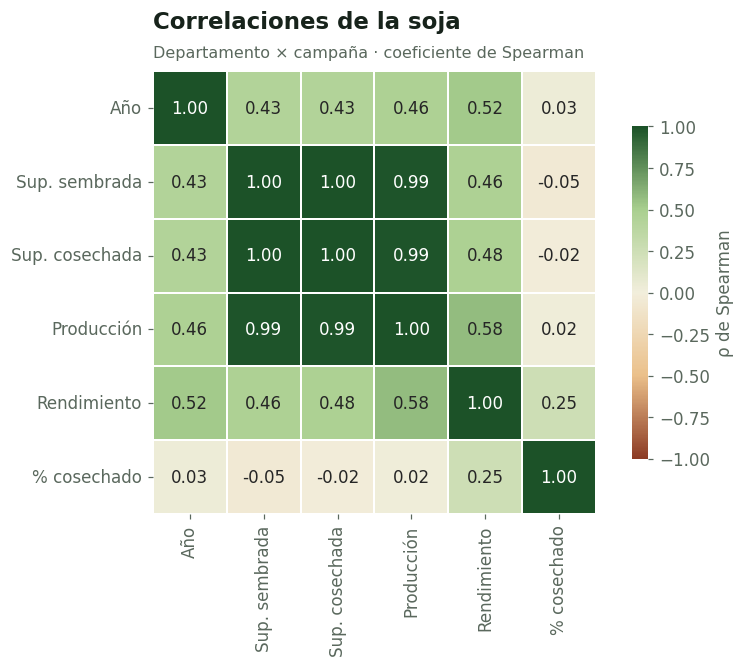

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 3.7  Correlaciones (soja, departamento × campaña)
# ─────────────────────────────────────────────────────────────────────────────
soja = df[(df['cultivo'] == 'soja total') & (df['superficie_cosechada_ha'] > 0)]
vars_corr = {'anio': 'Año', 'superficie_sembrada_ha': 'Sup. sembrada', 'superficie_cosechada_ha': 'Sup. cosechada',
             'produccion_tm': 'Producción', 'rendimiento_kgxha': 'Rendimiento', 'ratio_cosecha': '% cosechado'}
corr = soja[list(vars_corr)].rename(columns=vars_corr).corr(method='spearman')

fig, ax = plt.subplots(figsize=(8, 6.2))
sns.heatmap(corr, annot=True, fmt='.2f', cmap=CMAP_DIV, vmin=-1, vmax=1, square=True, linewidths=1,
            cbar_kws={'shrink': .75, 'label': 'ρ de Spearman'}, ax=ax)
ax.grid(False)
titulo(ax, 'Correlaciones de la soja', 'Departamento × campaña · coeficiente de Spearman')
plt.tight_layout(); plt.show()

**Lectura.**
- Superficie y producción están casi perfectamente correlacionadas: **el volumen lo explica la escala**. Por eso la producción no sirve como variable explicativa del rinde (sería circular).
- El **rendimiento crece con el año** (tendencia tecnológica) y con el **% cosechado** (las campañas con pérdidas de superficie suelen ser también de bajo rinde).
- La relación entre superficie y rendimiento es positiva pero moderada: los departamentos grandes suelen estar en las mejores zonas, pero la escala por sí sola no garantiza productividad.

## 3.8 Cobertura temporal

Antes de modelar conviene verificar que la cantidad de registros por campaña sea estable: un salto brusco podría indicar cambios de metodología de la fuente o una campaña incompleta.

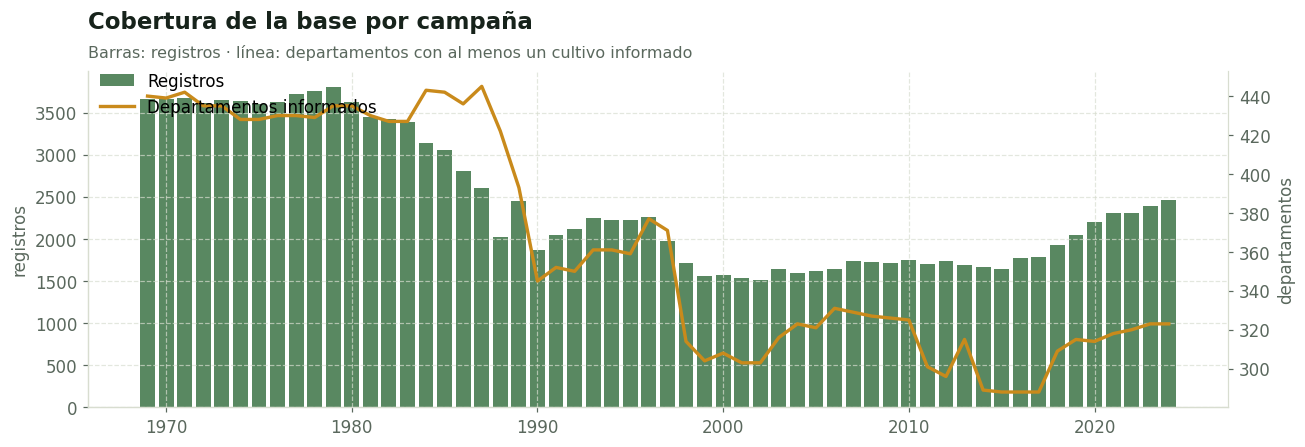

Última campaña (2024/2025): 2.462 registros, 109 % del promedio de las 5 anteriores.


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 3.8  Registros, cultivos y departamentos informados por campaña
# ─────────────────────────────────────────────────────────────────────────────
cob = df.groupby('anio').agg(registros=('cultivo', 'size'), cultivos=('cultivo', 'nunique'),
                             departamentos=('departamento_id', 'nunique'))
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.bar(cob.index, cob['registros'], color=VERDE, alpha=.8, label='Registros')
ax2 = ax.twinx()
ax2.plot(cob.index, cob['departamentos'], color=DORADO, lw=2.2, label='Departamentos informados')
ax2.grid(False); ax2.spines['right'].set_visible(True)
ax.set_ylabel('registros'); ax2.set_ylabel('departamentos')
titulo(ax, 'Cobertura de la base por campaña', 'Barras: registros · línea: departamentos con al menos un cultivo informado')
fig.legend(loc='upper left', bbox_to_anchor=(0.07, 0.86)); plt.tight_layout(); plt.show()
ult = cob.iloc[-1]
print(f'Última campaña ({ANIO_MAX}/{ANIO_MAX + 1}): {miles(ult["registros"])} registros, '
      f'{miles(ult["registros"] / cob["registros"].iloc[-6:-1].mean() * 100)} % del promedio de las 5 anteriores.')

**Lectura.** La cobertura es estable a lo largo de toda la serie, sin huecos. La última campaña tiene una cantidad de registros comparable a las anteriores, por lo que puede usarse en el análisis y como período de evaluación de los modelos.

## 3.9 Síntesis del análisis exploratorio

1. **Crecimiento sostenido con alta volatilidad.** La producción creció cerca del 2,4 % anual, pero con caídas abruptas en campañas de sequía.
2. **Concentración.** Soja, maíz y trigo explican la mayor parte del volumen, y Buenos Aires, Córdoba y Santa Fe la mayor parte del territorio productivo.
3. **Productividad.** El rendimiento de los granos aumentó de forma sostenida (el del maíz se triplicó): hay una tendencia tecnológica que los modelos deben capturar.
4. **Calidad del rinde.** Los valores extremos son reales y específicos de cada cultivo; se analizan por cultivo, nunca mezclados.
5. **Implicancia para el modelado.** La producción es superficie × rinde, así que el problema predictivo interesante es el **rendimiento**. Lo que más lo mueve de un año a otro (el clima) no está en la base, y eso fija un límite a lo que cualquier modelo puede lograr.

# Capítulo 4 · Visualización de datos

Este capítulo reúne los gráficos de síntesis del trabajo. Cada uno responde una pregunta concreta y se eligió el tipo de gráfico que mejor la contesta:

| Pregunta | Gráfico |
|:--|:--|
| ¿Cómo creció la producción y qué cultivos la impulsaron? | Área apilada por cultivo |
| ¿Qué cultivos y qué provincias pesan más? | Barras ordenadas y curva de Pareto |
| ¿Cómo se distribuye el rinde de cada cultivo? | Diagrama de caja (escala logarítmica) |
| ¿La escala explica el volumen? | Dispersión log-log |
| ¿En qué se especializa cada provincia? | Mapa de calor normalizado |
| ¿Qué campañas fueron excepcionales? | Mapa de calor de rinde relativo |
| ¿Dónde se produce y dónde se rinde más? | Mapas de Argentina por provincia y departamento |

Todas las figuras usan la misma paleta: cada cultivo conserva su color en todo el notebook y en el tablero.

## 4.1 Evolución de la producción por cultivo

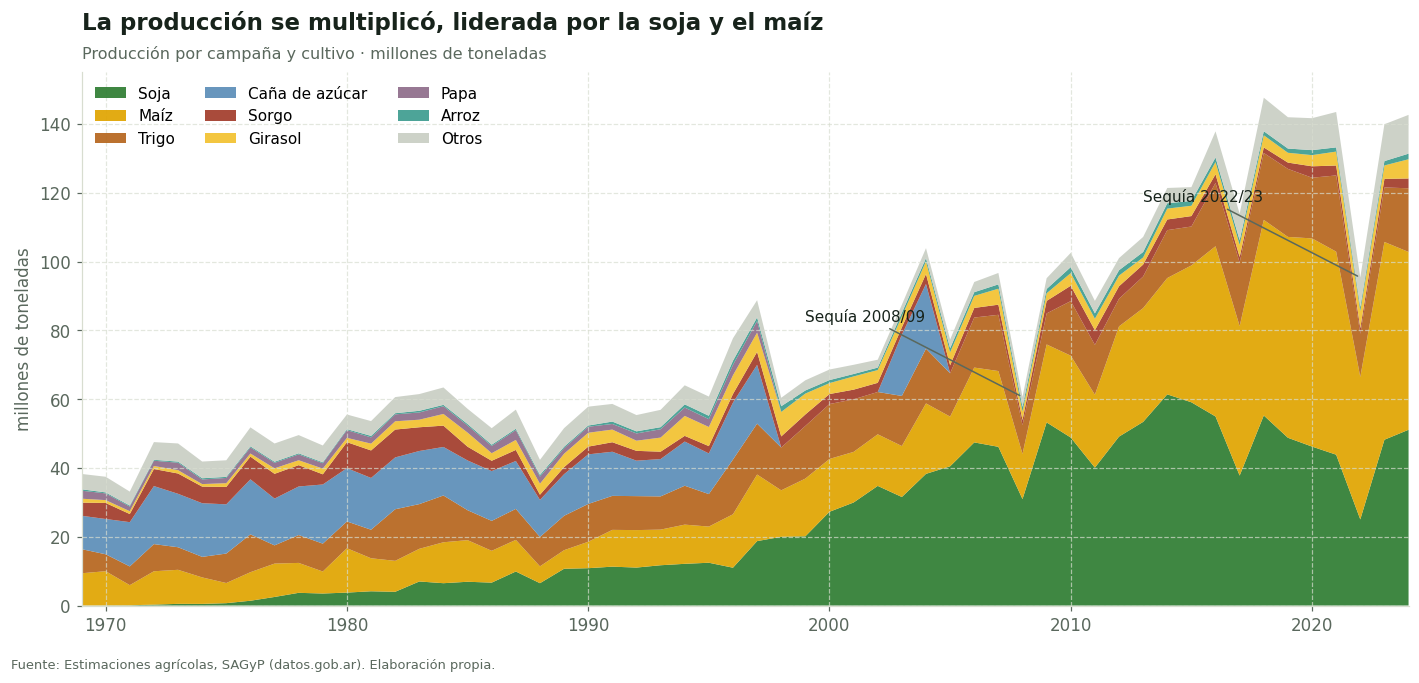

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 4.1  Área apilada: producción por campaña y cultivo
# ─────────────────────────────────────────────────────────────────────────────
top8 = df.groupby('cultivo')['produccion_tm'].sum().nlargest(8).index
piv = (df.assign(c=np.where(df['cultivo'].isin(top8), df['cultivo'], 'otros'))
         .pivot_table(index='anio', columns='c', values='produccion_tm', aggfunc='sum', fill_value=0))
piv = piv[list(top8) + ['otros']]

fig, ax = plt.subplots(figsize=(13, 6))
ax.stackplot(piv.index, piv.T.values / 1e6, labels=[nombre(c) for c in piv.columns],
             colors=[color(c) if c != 'otros' else '#C9CEC4' for c in piv.columns], alpha=.92, lw=0)
ax.set_xlim(piv.index.min(), piv.index.max()); ax.set_ylabel('millones de toneladas')
for a, txt in [(2008, 'Sequía 2008/09'), (2022, 'Sequía 2022/23')]:
    ax.annotate(txt, xy=(a, piv.loc[a].sum() / 1e6), xytext=(a - 9, piv.loc[a].sum() / 1e6 + 22),
                arrowprops=dict(arrowstyle='-', color=GRIS), color=TINTA, fontsize=10)
ax.legend(loc='upper left', ncol=3, fontsize=10)
titulo(ax, 'La producción se multiplicó, liderada por la soja y el maíz', 'Producción por campaña y cultivo · millones de toneladas')
fuente(fig); plt.tight_layout(); plt.show()

La soja pasa de ser marginal en los setenta a ser el cultivo dominante desde los noventa; el maíz acelera fuerte en la última década. Las dos sequías marcadas muestran cuánto puede caer la oferta total en una sola campaña.

## 4.2 Peso de cada cultivo y de cada provincia

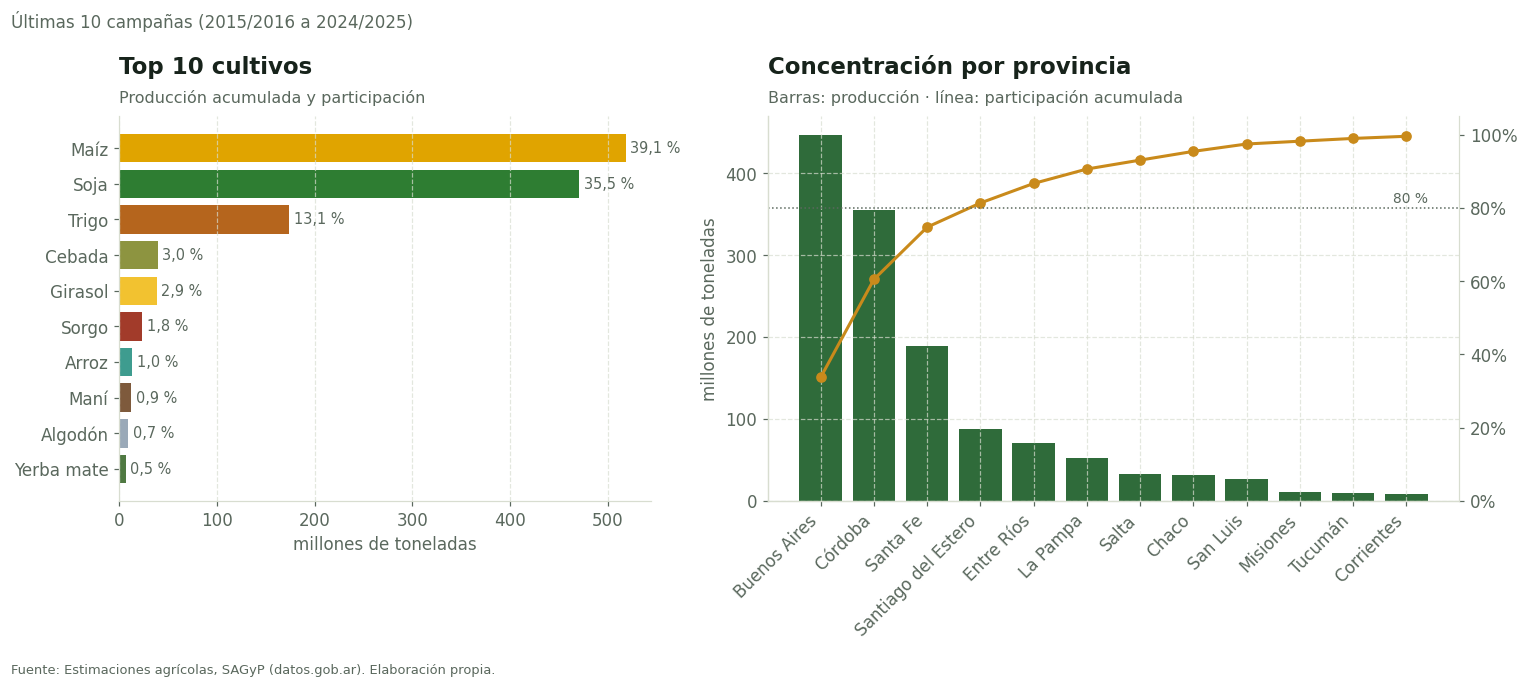

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 4.2  Barras ordenadas: cultivos y Pareto de provincias (últimas 10 campañas)
# ─────────────────────────────────────────────────────────────────────────────
ult10 = df[df['anio'] > ANIO_MAX - 10]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={'width_ratios': [1, 1.3]})

c = ult10.groupby('cultivo')['produccion_tm'].sum().nlargest(10)[::-1]
a1.barh([nombre(x) for x in c.index], c / 1e6, color=[color(x) for x in c.index])
for i, v in enumerate(c):
    a1.text(v / 1e6 + 5, i, f'{miles(v / ult10["produccion_tm"].sum() * 100, 1)} %', va='center', fontsize=9.5, color=GRIS)
a1.set_xlabel('millones de toneladas'); a1.grid(axis='y', visible=False)
titulo(a1, 'Top 10 cultivos', 'Producción acumulada y participación')

p = ult10.groupby('provincia_nombre')['produccion_tm'].sum().sort_values(ascending=False).head(12)
acum = p.cumsum() / ult10['produccion_tm'].sum() * 100
a2.bar(p.index, p / 1e6, color=VERDE)
a2.set_ylabel('millones de toneladas'); a2.tick_params(axis='x', rotation=45)
for lbl in a2.get_xticklabels(): lbl.set_ha('right')
a3 = a2.twinx(); a3.plot(p.index, acum, color=DORADO, marker='o', lw=2); a3.set_ylim(0, 105)
a3.axhline(80, color=GRIS, ls=':', lw=1); a3.text(len(p) - .6, 81.5, '80 %', color=GRIS, fontsize=9, ha='right')
a3.yaxis.set_major_formatter(mticker.PercentFormatter()); a3.grid(False); a3.spines['right'].set_visible(True)
titulo(a2, 'Concentración por provincia', 'Barras: producción · línea: participación acumulada')
fig.suptitle(f'Últimas 10 campañas ({ANIO_MAX - 9}/{ANIO_MAX - 8} a {ANIO_MAX}/{ANIO_MAX + 1})', x=0.01, ha='left', color=GRIS, fontsize=11)
fuente(fig); plt.tight_layout(); plt.show()

## 4.3 Distribución del rendimiento por cultivo

Cada caja resume los rindes departamentales de un cultivo (mediana, cuartiles y bigotes de 1,5 × IQR). Se usa **escala logarítmica** porque los cultivos tienen órdenes de magnitud distintos.

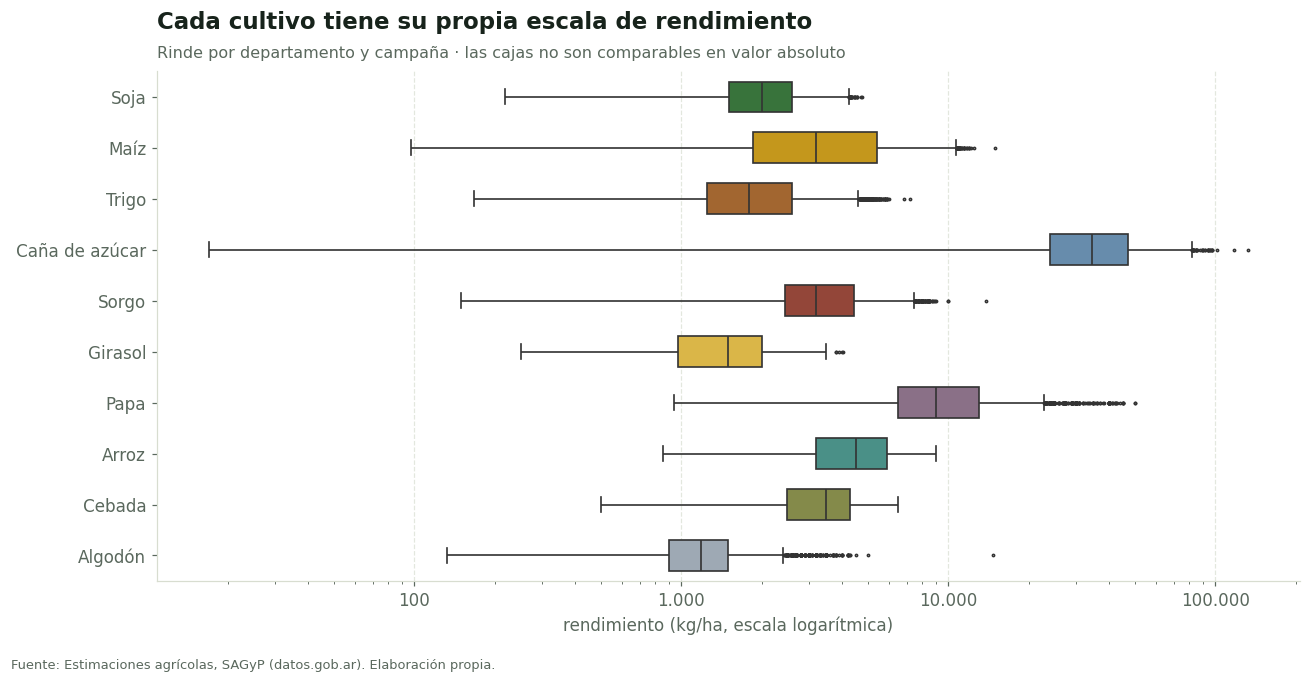

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 4.3  Boxplot de rendimiento por cultivo
# ─────────────────────────────────────────────────────────────────────────────
orden = list(df.groupby('cultivo')['produccion_tm'].sum().nlargest(10).index)
datos = rend[rend['cultivo'].isin(orden)]
fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(data=datos, y='cultivo', x='rendimiento_kgxha', order=orden, hue='cultivo', hue_order=orden,
            palette={c: color(c) for c in orden}, legend=False, fliersize=1.5, linewidth=1.1, width=.6, ax=ax)
ax.set_xscale('log'); ax.set_yticks(range(len(orden))); ax.set_yticklabels([nombre(c) for c in orden])
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, p: miles(v)))
ax.set_xlabel('rendimiento (kg/ha, escala logarítmica)'); ax.set_ylabel('')
titulo(ax, 'Cada cultivo tiene su propia escala de rendimiento', 'Rinde por departamento y campaña · las cajas no son comparables en valor absoluto')
fuente(fig); plt.tight_layout(); plt.show()

## 4.4 Escala y volumen

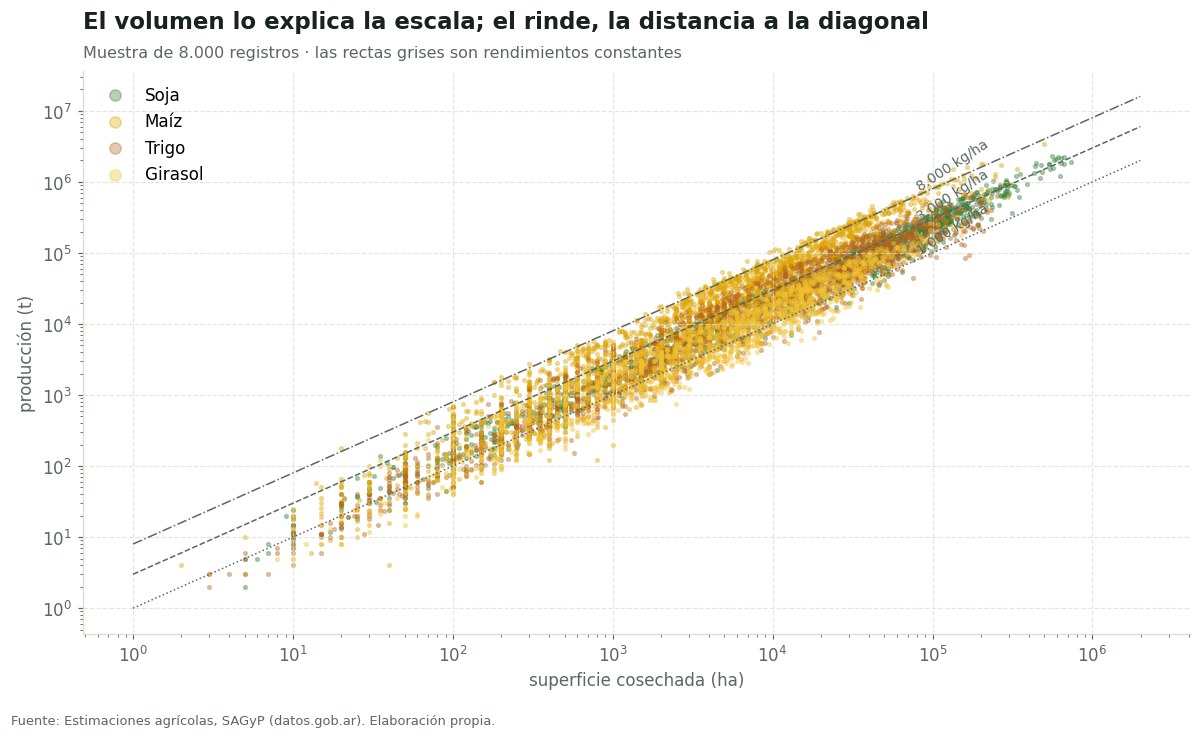

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 4.4  Dispersión log-log superficie cosechada vs. producción
# ─────────────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(11, 6.5))
muestra = df[df['cultivo'].isin(GRANDES) & (df['superficie_cosechada_ha'] > 0) & (df['produccion_tm'] > 0)]
muestra = muestra.sample(min(8000, len(muestra)), random_state=1)
for c in GRANDES:
    m = muestra[muestra['cultivo'] == c]
    ax.scatter(m['superficie_cosechada_ha'], m['produccion_tm'], s=6, alpha=.35, color=color(c), label=nombre(c))
xs = np.logspace(0, 6.3, 50)
for r, ls in [(1000, ':'), (3000, '--'), (8000, '-.')]:
    ax.plot(xs, xs * r / 1000, color=GRIS, lw=1, ls=ls)
    ax.text(xs[-12], xs[-12] * r / 1000 * 1.25, f'{miles(r)} kg/ha', color=GRIS, fontsize=9, rotation=33)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('superficie cosechada (ha)'); ax.set_ylabel('producción (t)')
ax.legend(markerscale=3, loc='upper left')
titulo(ax, 'El volumen lo explica la escala; el rinde, la distancia a la diagonal',
       'Muestra de 8.000 registros · las rectas grises son rendimientos constantes')
fuente(fig); plt.tight_layout(); plt.show()

En escala log-log, todos los puntos de un mismo rendimiento caen sobre una recta de pendiente 1. La nube del maíz queda por encima de la de soja y girasol porque su rinde por hectárea es mayor; la dispersión vertical dentro de cada cultivo es justamente lo que el capítulo 5 intenta predecir.

## 4.5 Especialización productiva de cada provincia

Un mapa de calor en toneladas absolutas solo mostraría que las provincias grandes producen mucho. Normalizado por fila (**cada provincia suma 100 %**) revela su **perfil**: en qué cultivos se especializa.

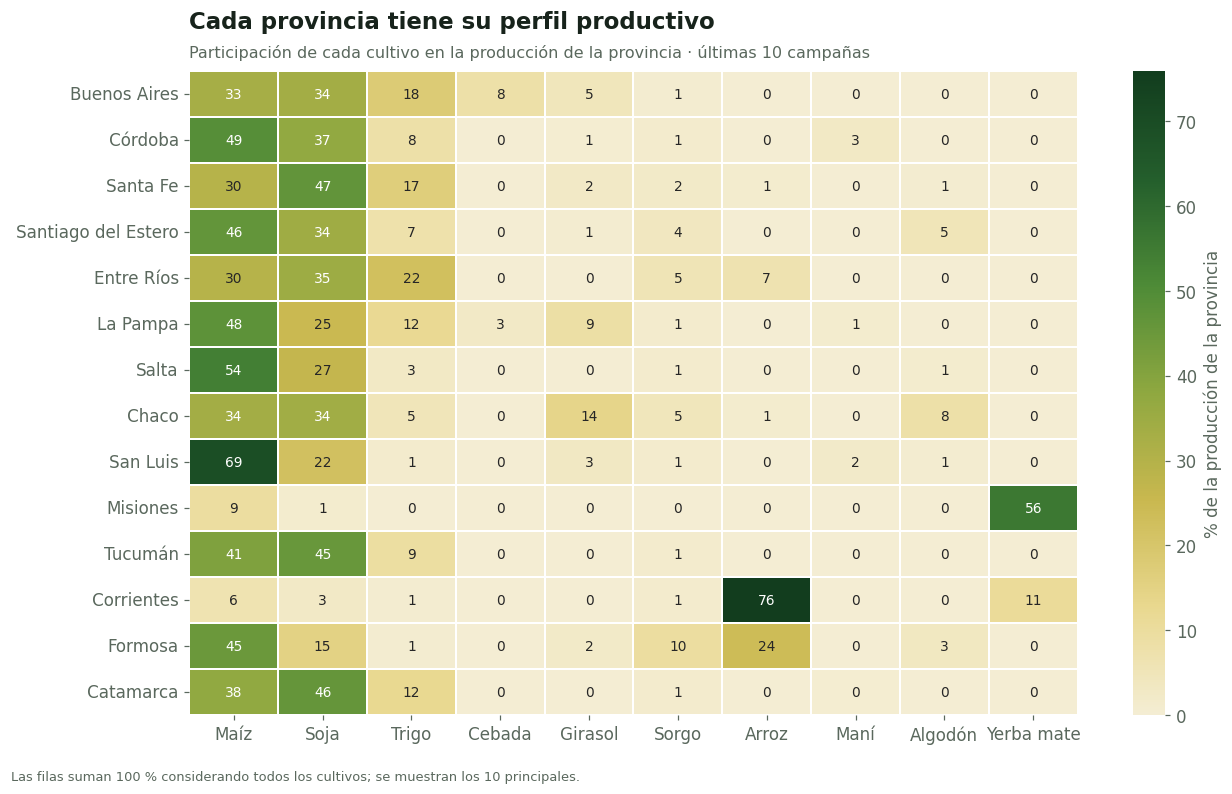

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 4.5  Mapa de calor provincia × cultivo, normalizado por provincia
# ─────────────────────────────────────────────────────────────────────────────
top_prov = ult10.groupby('provincia_nombre')['produccion_tm'].sum().nlargest(14).index
top_cult = ult10.groupby('cultivo')['produccion_tm'].sum().nlargest(10).index
mat = (ult10[ult10['provincia_nombre'].isin(top_prov)]
       .pivot_table(index='provincia_nombre', columns='cultivo', values='produccion_tm', aggfunc='sum', fill_value=0))
mat = mat.div(mat.sum(axis=1), axis=0)[top_cult].loc[top_prov] * 100
mat.columns = [nombre(c) for c in mat.columns]

fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(mat, annot=True, fmt='.0f', cmap=CMAP_AGRO, linewidths=1, linecolor='white',
            cbar_kws={'label': '% de la producción de la provincia'}, annot_kws={'fontsize': 9}, ax=ax)
ax.grid(False); ax.set_xlabel(''); ax.set_ylabel('')
titulo(ax, 'Cada provincia tiene su perfil productivo', 'Participación de cada cultivo en la producción de la provincia · últimas 10 campañas')
fuente(fig, 'Las filas suman 100 % considerando todos los cultivos; se muestran los 10 principales.')
plt.tight_layout(); plt.show()

La región pampeana se reparte entre soja, maíz y trigo; Tucumán y Jujuy están dominadas por la caña de azúcar; Misiones por la yerba mate y el té; Santiago del Estero, Chaco y Salta son casi enteramente soja y maíz, el sello de la expansión de la frontera agrícola.

## 4.6 Campañas excepcionales

Para comparar cultivos con rindes muy distintos se usa un **índice de rendimiento relativo**: el rinde nacional de cada campaña dividido por su tendencia de largo plazo (media móvil centrada de 9 campañas). Un valor de 100 es una campaña normal; 80 significa un 20 % por debajo de lo esperado.

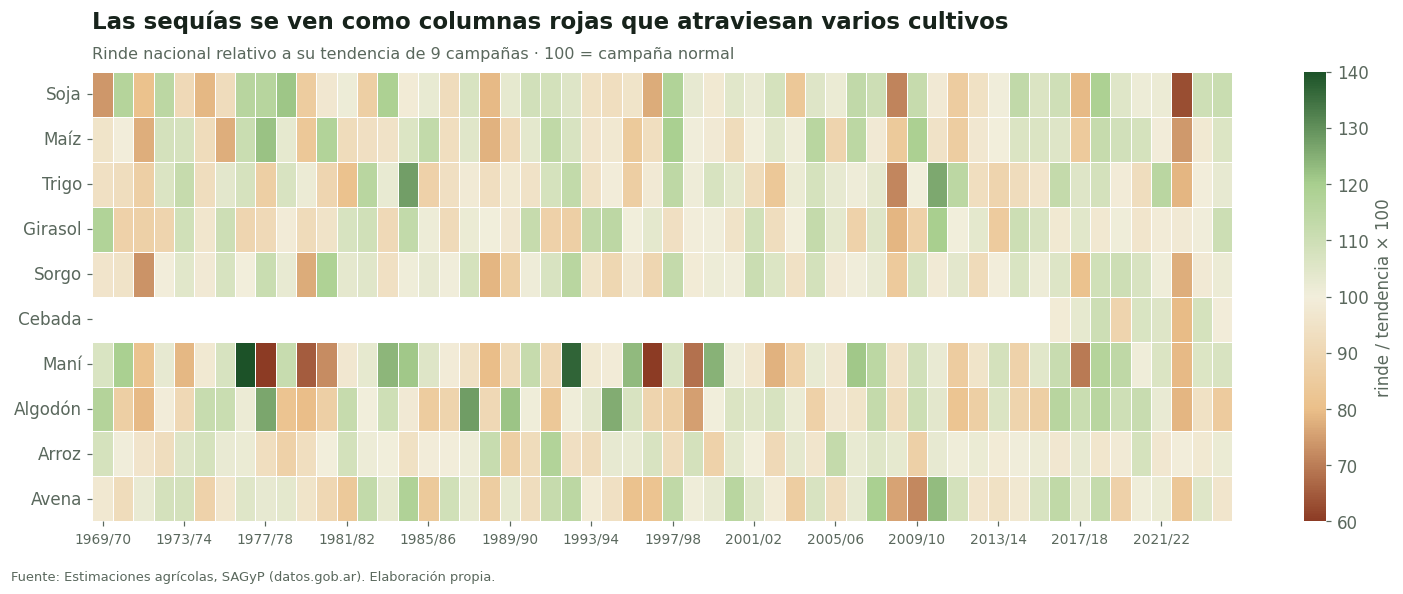

Campañas con peor rinde relativo promedio (soja, maíz y trigo): 2022/2023 (72) · 2008/2009 (76) · 1971/1972 (82) · 1988/1989 (84) · 1969/1970 (88)


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 4.6  Índice de rinde relativo a la tendencia, por cultivo y campaña
# ─────────────────────────────────────────────────────────────────────────────
cults_idx = ['soja total', 'maíz', 'trigo total', 'girasol', 'sorgo', 'cebada total', 'maní', 'algodón', 'arroz', 'avena']
idx = {}
for c in cults_idx:
    r = serie_rinde(df[df['cultivo'] == c])
    tendencia = r.rolling(9, center=True, min_periods=5).mean()
    idx[nombre(c)] = r / tendencia * 100
idx = pd.DataFrame(idx).T

fig, ax = plt.subplots(figsize=(14, 5.2))
sns.heatmap(idx, cmap=CMAP_DIV, center=100, vmin=60, vmax=140, linewidths=.4, linecolor='white',
            cbar_kws={'label': 'rinde / tendencia × 100'}, ax=ax)
ax.set_xticks(np.arange(0, idx.shape[1], 4) + .5)
ax.set_xticklabels([f'{a}/{str(a + 1)[-2:]}' for a in idx.columns[::4]], rotation=0, fontsize=9)
ax.grid(False); ax.set_xlabel(''); ax.set_ylabel('')
titulo(ax, 'Las sequías se ven como columnas rojas que atraviesan varios cultivos',
       'Rinde nacional relativo a su tendencia de 9 campañas · 100 = campaña normal')
fuente(fig); plt.tight_layout(); plt.show()
peores = idx.loc[['Soja', 'Maíz', 'Trigo']].mean().nsmallest(5)
print('Campañas con peor rinde relativo promedio (soja, maíz y trigo): ' +
      ' · '.join(f'{a}/{a + 1} ({miles(v)})' for a, v in peores.items()))

Este gráfico es la evidencia visual más clara de que existe un **factor común de campaña** (el clima) que golpea a varios cultivos a la vez. Volveremos sobre él en el capítulo 5.

## 4.7 Mapas de Argentina

Los límites de provincias y departamentos provienen del INDEC (censo 2010, versión simplificada publicada por el proyecto *geoAr*). El cruce con los datos se hace por **código INDEC**, no por nombre, para evitar problemas de tildes y denominaciones.

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 4.7  Carga de geometrías (provincias y departamentos)
# ─────────────────────────────────────────────────────────────────────────────
import geopandas as gpd
from shapely.ops import unary_union

GEO = 'https://raw.githubusercontent.com/PoliticaArgentina/data_warehouse/master/geoAr/data/'

def solo_poligonos(g):
    """Algunas geometrías vienen como colecciones mixtas: se conservan solo los polígonos."""
    if g is None or g.geom_type != 'GeometryCollection':
        return g
    return unary_union([p for p in g.geoms if p.geom_type in ('Polygon', 'MultiPolygon')])

geo_prov = gpd.read_file(GEO + 'provincias_simplified.geojson').rename(columns={'codprov_censo': 'provincia_id'})
geo_dep = gpd.read_file(GEO + 'censo2010_simplified.geojson').rename(columns={'link': 'departamento_id'})
geo_dep['geometry'] = geo_dep['geometry'].apply(solo_poligonos)
# Se excluye la Antártida y se recorta al territorio continental e insular
geo_prov = geo_prov.cx[-75:-53, -56:-21]
geo_dep = geo_dep[geo_dep.geometry.notna()].cx[-75:-53, -56:-21]

ids_dep = set(geo_dep['departamento_id'])
georef = df[df['departamento_id'].isin(ids_dep)]['produccion_tm'].sum() / df['produccion_tm'].sum() * 100
print(f'Provincias: {len(geo_prov)} · departamentos: {len(geo_dep)} · producción georreferenciable: {miles(georef, 1)} %')

def mapa(ax, gdf, columna, cmap=CMAP_AGRO, leyenda='', formato=None, **kw):
    gdf.plot(ax=ax, color='#EEF0E8', edgecolor='white', linewidth=.3)
    lk = {'shrink': .6, 'label': leyenda}
    if formato:
        lk['format'] = mticker.FuncFormatter(formato)
    gdf.dropna(subset=[columna]).plot(ax=ax, column=columna, cmap=cmap, edgecolor='white', linewidth=.25,
                                      legend=True, legend_kwds=lk, **kw)
    ax.set_axis_off(); ax.set_aspect('equal')

Provincias: 24 · departamentos: 526 · producción georreferenciable: 99,1 %


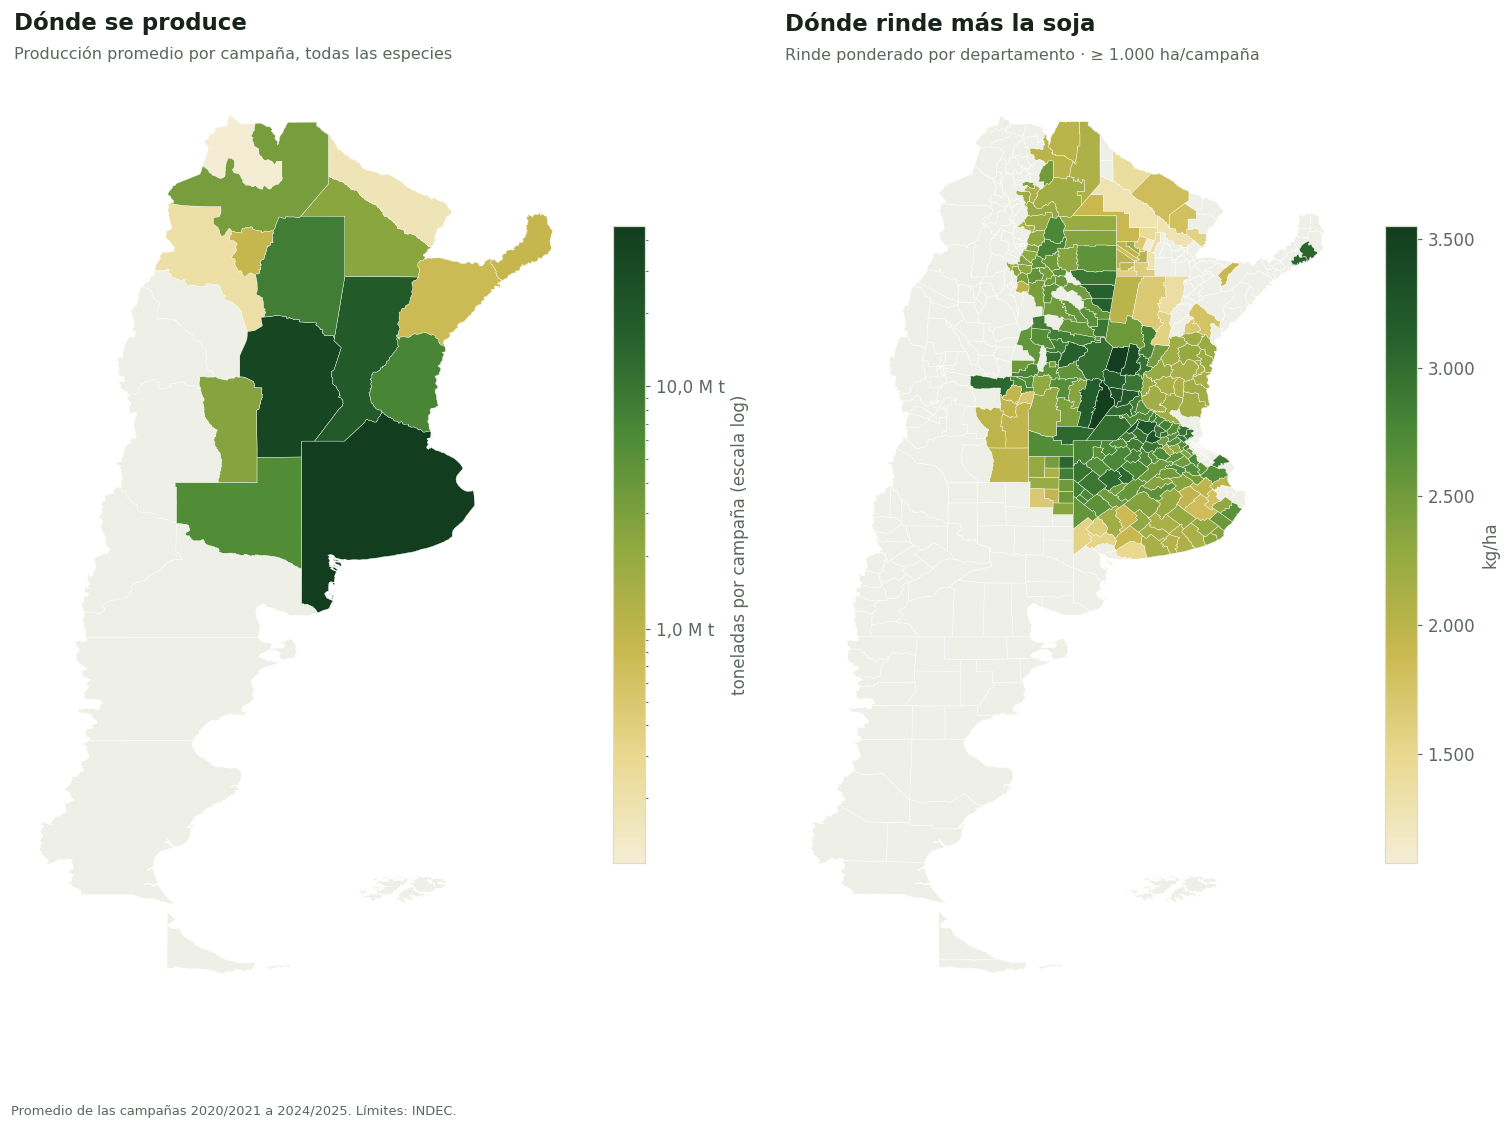

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 4.8  Producción por provincia y rinde de la soja por departamento (últimas 5 campañas)
# ─────────────────────────────────────────────────────────────────────────────
from matplotlib.colors import LogNorm
ult5 = df[df['anio'] > ANIO_MAX - 5]

prod_prov = ult5.groupby('provincia_id')['produccion_tm'].sum().div(5).rename('prod')
g1 = geo_prov.merge(prod_prov, on='provincia_id', how='left')

soja5 = ult5[(ult5['cultivo'] == 'soja total') & (ult5['superficie_cosechada_ha'] > 0)]
r_dep = soja5.groupby('departamento_id').agg(p=('produccion_tm', 'sum'), s=('superficie_cosechada_ha', 'sum'))
r_dep = r_dep[r_dep['s'] >= 5 * 1000]                      # al menos 1.000 ha por campaña
r_dep['rinde'] = r_dep['p'] * 1000 / r_dep['s']
g2 = geo_dep.merge(r_dep['rinde'], on='departamento_id', how='left')

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 10))
mapa(a1, g1, 'prod', leyenda='toneladas por campaña (escala log)', formato=lambda v, p: toneladas(v), norm=LogNorm(vmin=max(g1['prod'].min(), 1e3), vmax=g1['prod'].max()))
titulo(a1, 'Dónde se produce', 'Producción promedio por campaña, todas las especies')
mapa(a2, g2, 'rinde', leyenda='kg/ha', formato=lambda v, p: miles(v))
titulo(a2, 'Dónde rinde más la soja', 'Rinde ponderado por departamento · ≥ 1.000 ha/campaña')
fuente(fig, f'Promedio de las campañas {ANIO_MAX - 4}/{ANIO_MAX - 3} a {ANIO_MAX}/{ANIO_MAX + 1}. Límites: INDEC.')
plt.tight_layout(); plt.show()

El mapa de la izquierda confirma la concentración pampeana. El de la derecha agrega un matiz: dentro de la zona sojera, el rinde **no es homogéneo**. El núcleo (sur de Santa Fe, sudeste de Córdoba, norte de Buenos Aires) rinde bastante más que los bordes de la frontera agrícola. Esa heterogeneidad espacial es una de las señales que aprovecha el modelo del capítulo 5.

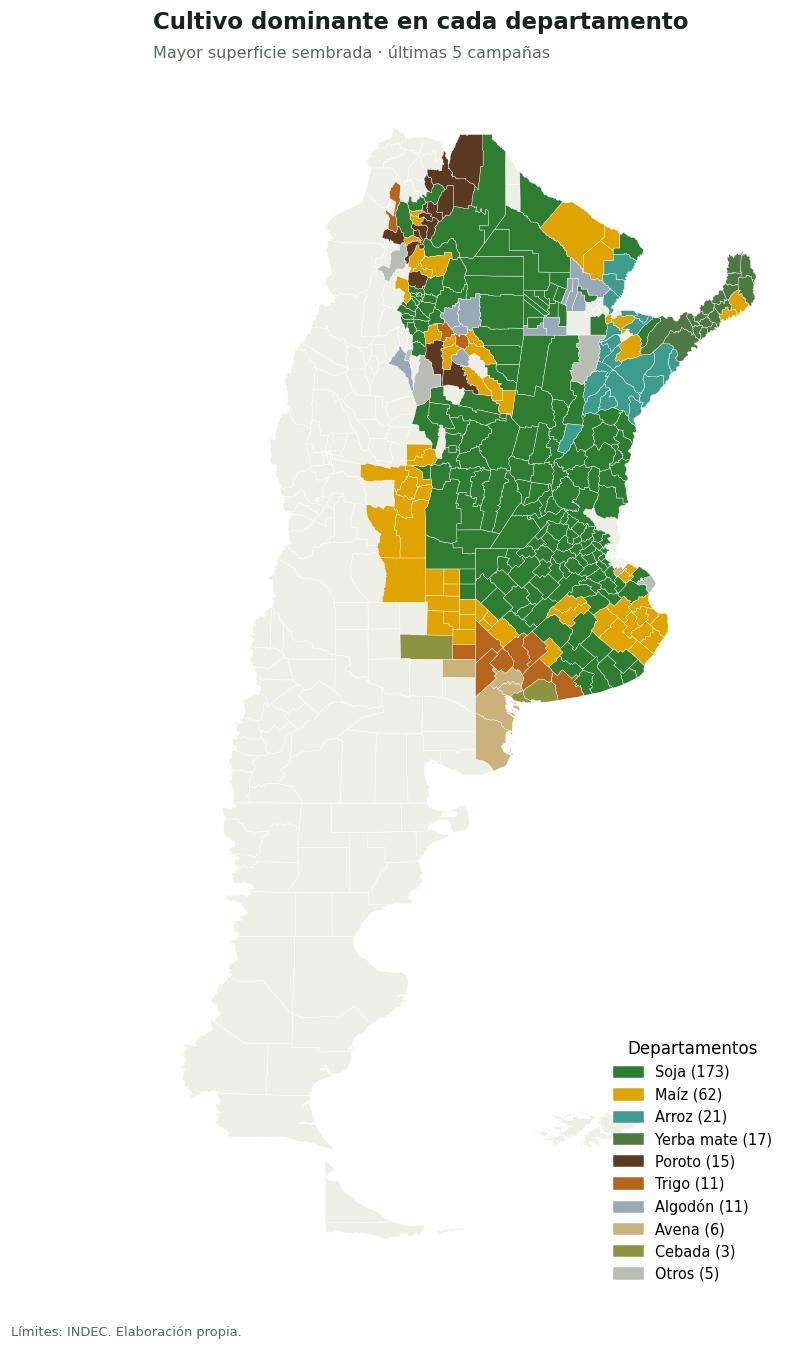

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 4.9  Cultivo dominante por departamento (por superficie sembrada, últimas 5 campañas)
# ─────────────────────────────────────────────────────────────────────────────
area = ult5.groupby(['departamento_id', 'cultivo'])['superficie_sembrada_ha'].sum().reset_index()
dom = area.loc[area.groupby('departamento_id')['superficie_sembrada_ha'].idxmax()].set_index('departamento_id')['cultivo']
g3 = geo_dep.merge(dom.rename('dominante'), on='departamento_id', how='left')
principales = g3['dominante'].value_counts().head(9).index
g3['dominante'] = np.where(g3['dominante'].isin(principales), g3['dominante'], np.where(g3['dominante'].notna(), 'otros', None))

fig, ax = plt.subplots(figsize=(8.5, 12))
g3.plot(ax=ax, color='#EEF0E8', edgecolor='white', linewidth=.3)
for c in list(principales) + ['otros']:
    sub = g3[g3['dominante'] == c]
    if len(sub):
        sub.plot(ax=ax, color=color(c) if c != 'otros' else '#B8BDB5', edgecolor='white', linewidth=.25)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=color(c) if c != 'otros' else '#B8BDB5', label=f'{nombre(c)} ({(g3["dominante"] == c).sum()})')
                   for c in list(principales) + ['otros']], loc='lower right', title='Departamentos', fontsize=9.5)
ax.set_axis_off()
titulo(ax, 'Cultivo dominante en cada departamento', 'Mayor superficie sembrada · últimas 5 campañas')
fuente(fig, 'Límites: INDEC. Elaboración propia.'); plt.tight_layout(); plt.show()

La soja domina el centro y norte del país; el maíz aparece en el oeste de la región pampeana y en el NOA; el trigo en el sur bonaerense; los cultivos regionales (caña, yerba, frutales, papa, ajo) definen el mapa en las economías extrapampeanas. Este mismo mapa, en versión interactiva y con línea de tiempo, está disponible en el tablero BI.

# Capítulo 5 · Modelos y ajustes de los datos

## 5.1 Planteo del problema predictivo

**Variable objetivo:** el rendimiento (kg/ha) de un cultivo en un departamento y una campaña. Se elige el rendimiento, y no la producción, porque la producción es casi una función de la superficie (capítulo 3): predecirla sería trivial y poco útil. El rendimiento, en cambio, mide productividad y es lo que se necesita para anticipar cosechas.

**Caso principal:** la **soja**, el cultivo de mayor peso. Al final del capítulo el mismo procedimiento se replica para maíz, trigo y girasol.

El capítulo evalúa **dos escenarios de uso** que difieren en qué información está disponible al momento de predecir:

| | Escenario A · Pronóstico anticipado | Escenario B · Estimación espacial |
|:--|:--|:--|
| **Pregunta** | ¿Qué rinde cabe esperar en cada departamento **antes** de la cosecha? | Conociendo cómo le fue al resto de la provincia **en esta campaña**, ¿cuánto rindió este departamento? |
| **Información** | Solo el historial del departamento, la superficie sembrada y la tendencia | Lo anterior **más** el rinde de los demás departamentos en la misma campaña |
| **Uso real** | Planificar logística, acopio y crédito | Completar estimaciones faltantes, revisar valores sospechosos, estimaciones tempranas cuando aún no reportaron todos los departamentos |

> **Nota metodológica: fuga de información (*data leakage*).** Un modelo que usa información que no estaría disponible al momento de predecir obtiene métricas excelentes en el notebook y falla en la realidad. Por eso **nunca** se usan la producción, la superficie cosechada ni el % cosechado de la **misma** campaña: todas se conocen recién al cosechar y la producción contiene al rinde por definición. Las variables de historial se calculan solo con campañas **anteriores**, y en el escenario B el contexto provincial **excluye al propio departamento** (*leave-one-out*).

## 5.2 Construcción del dataset de modelado

Para cada departamento se arma su serie anual completa (rellenando los años faltantes para que los rezagos sean correctos) y se calculan estas variables:

| Variable | Escenario | Descripción |
|:--|:--:|:--|
| `anio` | A y B | Captura la tendencia tecnológica |
| `provincia_id`, `region` | A y B | Ubicación (categóricas) |
| `rend_lag1`, `rend_lag2` | A y B | Rinde del departamento 1 y 2 campañas antes |
| `rend_media3`, `rend_media5` | A y B | Promedio de las 3 y 5 campañas anteriores |
| `rend_std5` | A y B | Variabilidad del rinde en las 5 campañas anteriores (riesgo del lugar) |
| `ratio_cos_lag1` | A y B | % cosechado en la campaña anterior |
| `log_sup`, `var_sup` | A y B | Superficie sembrada (escala log) y su cambio contra la campaña anterior |
| `rend_nac_lag1` | A y B | Rinde nacional de la campaña anterior |
| `n_hist` | A y B | Cantidad de campañas con historial |
| `rend_prov_loo` | B | Rinde de **los demás** departamentos de la provincia en la misma campaña |
| `rend_nac_loo` | B | Rinde nacional de la misma campaña, sin el propio departamento |
| `anom_prov` | B | Contexto provincial dividido por el promedio histórico del departamento: ¿es un año bueno o malo para la zona? |

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 5.2  Construcción de variables para el modelado
# ─────────────────────────────────────────────────────────────────────────────
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEMILLA = 42
OBJETIVO = 'rendimiento_kgxha'
VARS_A = ['anio', 'rend_lag1', 'rend_lag2', 'rend_media3', 'rend_media5', 'rend_std5', 'ratio_cos_lag1',
          'log_sup', 'var_sup', 'rend_nac_lag1', 'n_hist']
VARS_B = VARS_A + ['rend_prov_loo', 'rend_nac_loo', 'anom_prov']
CATEG = ['provincia_id', 'region']

def construir_dataset(cultivo, datos=df):
    """Una fila por departamento y campaña con variables de historial (solo pasado) y de contexto espacial."""
    d = datos[(datos['cultivo'] == cultivo) & (datos['superficie_cosechada_ha'] > 0) & (datos['rendimiento_kgxha'] > 0)
              & datos['departamento_id'].notna() & ~datos['departamento_id'].str.endswith('000', na=False)]
    d = d[['anio', 'provincia_id', 'departamento_id', 'superficie_sembrada_ha', 'superficie_cosechada_ha', OBJETIVO]]
    nacional = serie_rinde(datos[datos['cultivo'] == cultivo])
    bloques = []
    for dep, x in d.groupby('departamento_id'):
        x = x.set_index('anio').reindex(range(x['anio'].min(), x['anio'].max() + 1))
        x['departamento_id'] = dep
        x['provincia_id'] = x['provincia_id'].ffill().bfill()
        r = x[OBJETIVO]
        pasado = r.shift(1)
        x['rend_lag1'], x['rend_lag2'] = pasado, r.shift(2)
        x['rend_media3'] = pasado.rolling(3, min_periods=2).mean()
        x['rend_media5'] = pasado.rolling(5, min_periods=3).mean()
        x['rend_std5'] = pasado.rolling(5, min_periods=3).std()
        x['ratio_cos_lag1'] = (x['superficie_cosechada_ha'] / x['superficie_sembrada_ha']).shift(1)
        x['sup_lag1'] = x['superficie_sembrada_ha'].shift(1)
        x['n_hist'] = pasado.notna().cumsum()
        bloques.append(x.reset_index())
    m = pd.concat(bloques, ignore_index=True)
    m = m[m[OBJETIVO].notna()].copy()
    m['rend_nac_lag1'] = m['anio'].map(nacional.shift(1))
    m['log_sup'] = np.log1p(m['superficie_sembrada_ha'])
    m['var_sup'] = m['log_sup'] - np.log1p(m['sup_lag1'])
    m['region'] = m['provincia_id'].map(prov_region)
    # Contexto espacial de la misma campaña, excluyendo al propio departamento (leave-one-out)
    m['_p'] = m[OBJETIVO] * m['superficie_cosechada_ha']
    g = m.groupby(['provincia_id', 'anio'])
    sp, ss, n = g['_p'].transform('sum'), g['superficie_cosechada_ha'].transform('sum'), g['_p'].transform('size')
    m['rend_prov_loo'] = np.where(n > 1, (sp - m['_p']) / (ss - m['superficie_cosechada_ha']), np.nan)
    gn = m.groupby('anio')
    m['rend_nac_loo'] = (gn['_p'].transform('sum') - m['_p']) / (gn['superficie_cosechada_ha'].transform('sum') - m['superficie_cosechada_ha'])
    m['anom_prov'] = m['rend_prov_loo'] / m['rend_media5'].fillna(m['rend_media3'])
    m = m.drop(columns=['_p']).dropna(subset=['rend_lag1', 'rend_media3', 'rend_nac_lag1'])
    return m.reset_index(drop=True)

ds = construir_dataset('soja total')
print(f'Dataset de soja: {miles(len(ds))} filas · {ds["departamento_id"].nunique()} departamentos · campañas {ds["anio"].min()}–{ds["anio"].max()}')
display(ds[['anio', 'departamento_id', OBJETIVO] + VARS_B[1:]].sample(5, random_state=1))

Dataset de soja: 10.427 filas · 319 departamentos · campañas 1971–2024


,anio,departamento_id,rendimiento_kgxha,rend_lag1,rend_lag2,rend_media3,rend_media5,rend_std5,ratio_cos_lag1,log_sup,var_sup,rend_nac_lag1,n_hist,rend_prov_loo,rend_nac_loo,anom_prov
7381,1994,42147,"1.404,00","1.182,00","2.000,00","1.496,67","1.368,20","378,59","1,00","6,80","-0,20","2.038,63",13,"1.596,21","2.044,69","1,17"
9956,2023,86154,"2.581,00","2.660,00","3.199,00","3.098,00","3.093,20","284,94","1,00","9,29","-0,69","1.744,45",38,"2.743,62","2.945,22","0,89"
9041,2020,82084,"2.079,00","2.267,00","3.795,00","2.707,00","2.975,80","784,41","0,95","11,29","-0,13","2.919,10",51,"3.080,88","2.810,42","1,04"
7976,2023,66049,"2.350,00","1.552,00","1.779,00","2.010,33","2.196,40","524,33","1,00","7,48","-0,80","1.744,45",28,"2.263,29","2.945,05","1,03"
9467,2012,86028,"1.700,00","800,00","1.500,00","1.150,00",NaN,NaN,"0,75","7,72","-0,29","2.281,63",2,"1.561,03","2.548,57","1,36"


## 5.3 Partición temporal y métricas

En series de tiempo **no se puede mezclar al azar** campañas de entrenamiento y de prueba: el modelo vería el futuro. Se usa una partición cronológica:

| Conjunto | Campañas | Uso |
|:--|:--|:--|
| Entrenamiento | hasta 2014/15 | Ajustar los modelos |
| Validación | 2015/16 a 2019/20 | Elegir modelo e hiperparámetros |
| Prueba (*test*) | 2020/21 a 2024/25 | Evaluación final, una sola vez. Incluye la sequía 2022/23 |

**Métricas:**
- **MAE** (error absoluto medio, kg/ha): cuánto se equivoca el modelo en promedio. Es la métrica principal porque se interpreta directamente.
- **RMSE** (kg/ha): penaliza más los errores grandes.
- **MAPE** (%): error relativo al rinde real.
- **R²**: proporción de la variabilidad del rinde que explica el modelo (1 = perfecto, 0 = igual que predecir el promedio, negativo = peor que el promedio).

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 5.3  Partición temporal y funciones de evaluación
# ─────────────────────────────────────────────────────────────────────────────
FIN_TRAIN, FIN_VALID = 2014, 2019

def particion(d):
    return d[d['anio'] <= FIN_TRAIN], d[(d['anio'] > FIN_TRAIN) & (d['anio'] <= FIN_VALID)], d[d['anio'] > FIN_VALID]

def metricas(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    ok = ~np.isnan(p)
    y, p = y[ok], p[ok]
    return {'MAE': mean_absolute_error(y, p), 'RMSE': mean_squared_error(y, p) ** .5,
            'MAPE %': np.mean(np.abs((y - p) / y)) * 100, 'R²': r2_score(y, p), 'n': len(y)}

tr, va, te = particion(ds)
print(f'Entrenamiento: {miles(len(tr))} filas · Validación: {miles(len(va))} · Prueba: {miles(len(te))}')

Entrenamiento: 7.776 filas · Validación: 1.301 · Prueba: 1.350


## 5.4 Líneas de base

Un modelo solo vale la pena si le gana a reglas simples que cualquier analista podría aplicar sin Machine Learning:

- **Último valor:** el rinde de la campaña anterior del mismo departamento.
- **Promedio de 3 o 5 campañas:** el rinde histórico reciente del departamento.
- **Rinde provincial de la campaña** (solo escenario B): el rinde de los demás departamentos de la provincia en el mismo año.

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 5.4  Líneas de base en validación y prueba
# ─────────────────────────────────────────────────────────────────────────────
BASES = {'Último valor': 'rend_lag1', 'Promedio 3 campañas': 'rend_media3',
         'Promedio 5 campañas': 'rend_media5', 'Rinde provincial de la campaña (B)': 'rend_prov_loo'}
tabla_base = pd.DataFrame({(conj, nom): metricas(d[OBJETIVO], d[col]) for conj, d in [('validación', va), ('prueba', te)]
                           for nom, col in BASES.items()}).T
display(tabla_base.style.format('{:,.1f}').format('{:,.3f}', subset=['R²']).format('{:,.0f}', subset=['n']))

**Lectura.** El promedio de varias campañas es una base exigente para el pronóstico anticipado: suaviza los años extremos. En el período de prueba ninguna regla basada solo en el historial supera un R² cercano a 0, porque ese período incluye la sequía 2022/23, que ningún historial puede anticipar. En cambio, conocer el rinde del resto de la provincia en la misma campaña reduce mucho el error: es la señal del clima de ese año.

## 5.5 Modelos candidatos

Se comparan tres familias con supuestos distintos:

1. **Regresión Ridge:** lineal con regularización L2. Variables numéricas estandarizadas y categóricas en *one-hot*. Simple, interpretable y robusta.
2. **Random Forest:** promedio de cientos de árboles de decisión entrenados sobre muestras distintas. Captura no linealidades e interacciones.
3. **Gradient Boosting (HistGradientBoosting):** árboles que se agregan secuencialmente corrigiendo los errores de los anteriores. Suele ser el más preciso en datos tabulares y maneja valores faltantes de forma nativa.

Primero se entrenan con hiperparámetros por defecto razonables, sobre entrenamiento, y se evalúan en validación.

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 5.5  Definición y comparación inicial de modelos
# ─────────────────────────────────────────────────────────────────────────────
# Categorías fijas para todo el país: así un modelo entrenado reconoce cualquier provincia o región
CATEGORIAS = {'provincia_id': sorted(df['provincia_id'].dropna().unique()), 'region': sorted(REGIONES)}

def preparar_X(d, variables):
    X = d[variables + CATEG].copy()
    for c in CATEG:
        X[c] = pd.Categorical(X[c], categories=CATEGORIAS[c])
    return X

def crear_modelo(tipo, variables, **params):
    if tipo == 'Ridge':
        pre = ColumnTransformer([('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), variables),
                                 ('cat', OneHotEncoder(handle_unknown='ignore'), CATEG)])
        return make_pipeline(pre, Ridge(alpha=params.get('alpha', 1.0)))
    if tipo == 'Random Forest':
        pre = ColumnTransformer([('num', SimpleImputer(strategy='median'), variables),
                                 ('cat', OneHotEncoder(handle_unknown='ignore'), CATEG)])
        return make_pipeline(pre, RandomForestRegressor(n_estimators=params.get('n_estimators', 300),
                                                        min_samples_leaf=params.get('min_samples_leaf', 5),
                                                        max_features=params.get('max_features', 1.0),
                                                        n_jobs=-1, random_state=SEMILLA))
    return HistGradientBoostingRegressor(learning_rate=params.get('learning_rate', 0.05), max_iter=params.get('max_iter', 400),
                                         max_leaf_nodes=params.get('max_leaf_nodes', 31), min_samples_leaf=params.get('min_samples_leaf', 20),
                                         l2_regularization=params.get('l2_regularization', 0.0),
                                         categorical_features='from_dtype', random_state=SEMILLA)

ESCENARIOS = {'A · anticipado': VARS_A, 'B · espacial': VARS_B}
TIPOS = ['Ridge', 'Random Forest', 'Gradient Boosting']

inicial = {}
for esc, variables in ESCENARIOS.items():
    for tipo in TIPOS:
        t0 = time.time()
        mod = crear_modelo(tipo, variables).fit(preparar_X(tr, variables), tr[OBJETIVO])
        inicial[(esc, tipo)] = {**metricas(va[OBJETIVO], mod.predict(preparar_X(va, variables))), 'segundos': time.time() - t0}
inicial = pd.DataFrame(inicial).T
display(inicial.style.format('{:,.1f}').format('{:,.3f}', subset=['R²']).format('{:,.0f}', subset=['n'])
        .highlight_min(subset=['MAE'], color='#E1ECDA'))

## 5.6 Ajuste de hiperparámetros

Los hiperparámetros controlan la complejidad del modelo: un modelo demasiado simple no aprende los patrones (*subajuste*) y uno demasiado complejo memoriza el ruido del entrenamiento (*sobreajuste*). Se prueban combinaciones con **búsqueda en grilla**, entrenando siempre con las campañas de entrenamiento y midiendo el MAE en las de validación. El conjunto de prueba no se toca en esta etapa.

Además del modelo, se prueba un **ajuste de la variable objetivo**: en lugar de predecir el rinde en kg/ha, predecir el **rinde relativo** al promedio de 5 campañas del departamento (`rinde / rend_media5`) y luego volver a kg/ha. Así el modelo aprende "qué tan buena es esta campaña para este lugar" y no tiene que aprender el nivel de cada departamento.

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 5.6  Búsqueda en grilla sobre el conjunto de validación
# ─────────────────────────────────────────────────────────────────────────────
from itertools import product

GRILLAS = {
    'Ridge': [{'alpha': a} for a in [1, 10, 100, 300, 1000]],
    'Random Forest': [{'min_samples_leaf': l, 'max_features': f, 'n_estimators': 200} for l, f in product([5, 30], [0.4, 1.0])],
    'Gradient Boosting': [{'learning_rate': lr, 'max_leaf_nodes': hj, 'min_samples_leaf': 40, 'l2_regularization': 1.0}
                          for lr, hj in product([0.03, 0.08], [15, 31, 63])],
}

def base_relativa(d):
    return d['rend_media5'].fillna(d['rend_media3'])

def entrenar(tipo, variables, params, d_tr, objetivo_relativo):
    y = d_tr[OBJETIVO] / base_relativa(d_tr) if objetivo_relativo else d_tr[OBJETIVO]
    return crear_modelo(tipo, variables, **params).fit(preparar_X(d_tr, variables), y)

def predecir(modelo, variables, d, objetivo_relativo):
    p = modelo.predict(preparar_X(d, variables))
    return p * base_relativa(d).values if objetivo_relativo else p

resultados = []
t0 = time.time()
for esc, variables in ESCENARIOS.items():
    for tipo, grilla in GRILLAS.items():
        for params in grilla:
            for rel in (False, True):
                m = entrenar(tipo, variables, params, tr, rel)
                r = metricas(va[OBJETIVO], predecir(m, variables, va, rel))
                resultados.append({'escenario': esc, 'modelo': tipo, 'objetivo': 'relativo' if rel else 'kg/ha',
                                   'hiperparámetros': params, **r})
busqueda = pd.DataFrame(resultados)
print(f'{len(busqueda)} configuraciones evaluadas en {time.time() - t0:.0f} s')

mejores = busqueda.loc[busqueda.groupby(['escenario', 'modelo'])['MAE'].idxmin()].sort_values(['escenario', 'MAE'])
display(mejores[['escenario', 'modelo', 'objetivo', 'hiperparámetros', 'MAE', 'RMSE', 'MAPE %', 'R²']]
        .style.format({'MAE': '{:,.1f}', 'RMSE': '{:,.1f}', 'MAPE %': '{:,.1f}', 'R²': '{:,.3f}'}).hide(axis='index'))

ganador = {esc: mejores[mejores['escenario'] == esc].iloc[0] for esc in ESCENARIOS}
nota('**Configuraciones elegidas en validación:** ' + ' · '.join(
    f'escenario {esc}: **{g["modelo"]}** (objetivo {g["objetivo"]}, {g["hiperparámetros"]}, MAE {miles(g["MAE"])} kg/ha)'
    for esc, g in ganador.items()))

60 configuraciones evaluadas en 187 s


escenario,modelo,objetivo,hiperparámetros,MAE,RMSE,MAPE %,R²
A · anticipado,Ridge,kg/ha,{'alpha': 300},469.4,581.9,19.8,0.304
A · anticipado,Random Forest,kg/ha,"{'min_samples_leaf': 30, 'max_features': 0.4, 'n_estimators': 200}",479.7,606.7,20.0,0.243
A · anticipado,Gradient Boosting,relativo,"{'learning_rate': 0.03, 'max_leaf_nodes': 15, 'min_samples_leaf': 40, 'l2_regularization': 1.0}",525.9,689.2,22.6,0.024
B · espacial,Ridge,kg/ha,{'alpha': 100},292.3,380.9,12.8,0.702
B · espacial,Random Forest,kg/ha,"{'min_samples_leaf': 30, 'max_features': 0.4, 'n_estimators': 200}",320.6,431.0,14.0,0.618
B · espacial,Gradient Boosting,relativo,"{'learning_rate': 0.03, 'max_leaf_nodes': 15, 'min_samples_leaf': 40, 'l2_regularization': 1.0}",340.9,443.8,14.5,0.595


**Configuraciones elegidas en validación:** escenario A · anticipado: **Ridge** (objetivo kg/ha, {'alpha': 300}, MAE 469 kg/ha) · escenario B · espacial: **Ridge** (objetivo kg/ha, {'alpha': 100}, MAE 292 kg/ha)

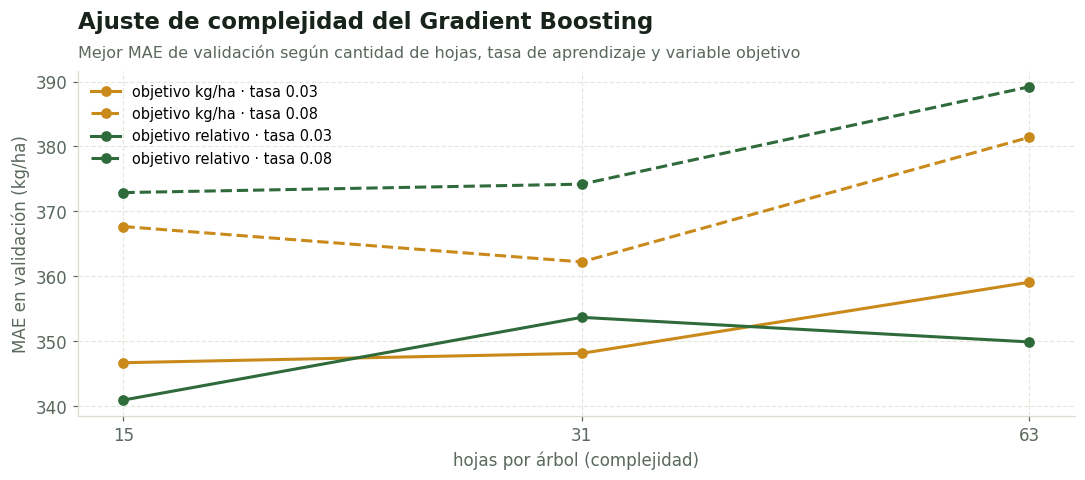

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 5.6 b  Curva de validación: complejidad vs. error (Gradient Boosting, escenario B)
# ─────────────────────────────────────────────────────────────────────────────
cv = busqueda[(busqueda['modelo'] == 'Gradient Boosting') & (busqueda['escenario'] == 'B · espacial')].copy()
cv['hojas'] = cv['hiperparámetros'].apply(lambda p: p['max_leaf_nodes'])
cv['tasa'] = cv['hiperparámetros'].apply(lambda p: p['learning_rate'])
fig, ax = plt.subplots(figsize=(10, 4.5))
for (obj, tasa), g in cv.groupby(['objetivo', 'tasa']):
    s = g.groupby('hojas')['MAE'].min()
    ax.plot(s.index, s.values, marker='o', lw=2, label=f'objetivo {obj} · tasa {tasa}',
            color=VERDE if obj == 'relativo' else DORADO, ls='-' if tasa == 0.03 else '--')
ax.set_xscale('log', base=2); ax.set_xticks([15, 31, 63]); ax.set_xticklabels(['15', '31', '63'])
ax.set_xlabel('hojas por árbol (complejidad)'); ax.set_ylabel('MAE en validación (kg/ha)')
ax.legend(fontsize=9.5)
titulo(ax, 'Ajuste de complejidad del Gradient Boosting', 'Mejor MAE de validación según cantidad de hojas, tasa de aprendizaje y variable objetivo')
plt.tight_layout(); plt.show()

**Lectura.** El resultado más interesante de la búsqueda es que **el modelo más simple, la regresión Ridge, gana en ambos escenarios**, y con una regularización fuerte. Los modelos de árboles, más flexibles, no logran sacar ventaja: con unas pocas variables muy informativas y relaciones aproximadamente lineales (el rinde de este año se parece al promedio reciente, corregido por cómo le va a la zona), la flexibilidad extra se traduce en ajustar ruido. Es un buen recordatorio de que la complejidad tiene que justificarse con datos de validación, no darse por sentada.

## 5.7 Evaluación final en el conjunto de prueba

Con la configuración elegida en validación, cada modelo se **reentrena con entrenamiento + validación** (hasta 2019/20) y se evalúa **una única vez** en las campañas 2020/21 a 2024/25, que nunca participaron de ninguna decisión.

**En números:** escenario A, MAE 541 kg/ha contra 545 del promedio de 5 campañas; escenario B, MAE 326 kg/ha (R² 0,65) contra 347 del rinde provincial. Pasar de A a B reduce el error un 40 %.

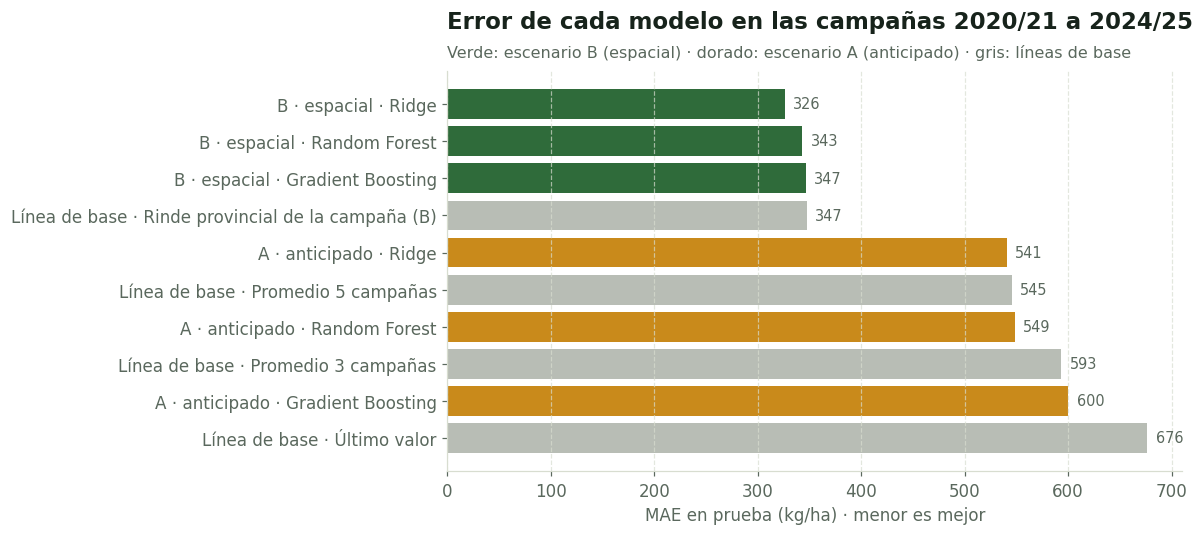

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 5.7  Reentrenamiento y evaluación final
# ─────────────────────────────────────────────────────────────────────────────
trva = pd.concat([tr, va])
finales, predicciones_test = {}, {}
for _, fila in mejores.iterrows():
    esc, tipo, rel = fila['escenario'], fila['modelo'], fila['objetivo'] == 'relativo'
    variables = ESCENARIOS[esc]
    m = entrenar(tipo, variables, fila['hiperparámetros'], trva, rel)
    p = predecir(m, variables, te, rel)
    predicciones_test[(esc, tipo)] = p
    finales[(esc, tipo)] = metricas(te[OBJETIVO], p)
for nom, col in BASES.items():
    finales[('Línea de base', nom)] = metricas(te[OBJETIVO], te[col])
finales = pd.DataFrame(finales).T

mejor_base_A = finales.loc[('Línea de base', 'Promedio 5 campañas'), 'MAE']
mejor_base_B = finales.loc[('Línea de base', 'Rinde provincial de la campaña (B)'), 'MAE']
finales['mejora vs. base %'] = [
    (1 - r['MAE'] / (mejor_base_B if e.startswith('B') else mejor_base_A)) * 100 if e != 'Línea de base' else np.nan
    for (e, _), r in finales.iterrows()]
display(finales.style.format('{:,.1f}').format('{:,.3f}', subset=['R²']).format('{:,.0f}', subset=['n'])
        .background_gradient(cmap=CMAP_AGRO.reversed(), subset=['MAE']))
mA = finales.loc[('A · anticipado', ganador['A · anticipado']['modelo'])]
mB = finales.loc[('B · espacial', ganador['B · espacial']['modelo'])]
nota(f'**En números:** escenario A, MAE {miles(mA["MAE"])} kg/ha contra {miles(mejor_base_A)} del promedio de 5 campañas; '
     f'escenario B, MAE {miles(mB["MAE"])} kg/ha (R² {miles(mB["R²"], 2)}) contra {miles(mejor_base_B)} del rinde provincial. '
     f'Pasar de A a B reduce el error un {miles((1 - mB["MAE"] / mA["MAE"]) * 100)} %.')

fig, ax = plt.subplots(figsize=(11, 5))
orden_f = finales.sort_values('MAE')
cols = [VERDE if e.startswith('B') else DORADO if e.startswith('A') else '#B8BDB5' for e, _ in orden_f.index]
ax.barh([f'{e} · {m}' for e, m in orden_f.index][::-1], orden_f['MAE'][::-1], color=cols[::-1])
for i, v in enumerate(orden_f['MAE'][::-1]):
    ax.text(v + 8, i, miles(v), va='center', fontsize=9.5, color=GRIS)
ax.set_xlabel('MAE en prueba (kg/ha) · menor es mejor'); ax.grid(axis='y', visible=False)
titulo(ax, 'Error de cada modelo en las campañas 2020/21 a 2024/25',
       'Verde: escenario B (espacial) · dorado: escenario A (anticipado) · gris: líneas de base')
plt.tight_layout(); plt.show()

**Lectura.**
- **Escenario A (anticipado).** El mejor modelo **empata** con el promedio de las últimas 5 campañas del departamento. No es un fracaso del modelado: es un **hallazgo**. Con la información disponible antes de la cosecha, el rendimiento de una campaña puntual es en buena medida impredecible porque depende del clima, y el período de prueba incluye una de las peores sequías de la historia.
- **Escenario B (espacial).** Agregar el contexto de la campaña cambia el panorama: el error cae cerca de un 40 % respecto del escenario A y el modelo también supera a la regla "usar el rinde provincial", porque aprende a **calibrar ese contexto con la historia de cada departamento** (uno que suele rendir por encima de su provincia lo sigue haciendo).

## 5.8 ¿Dónde se equivoca el modelo? Error por campaña y real vs. predicho

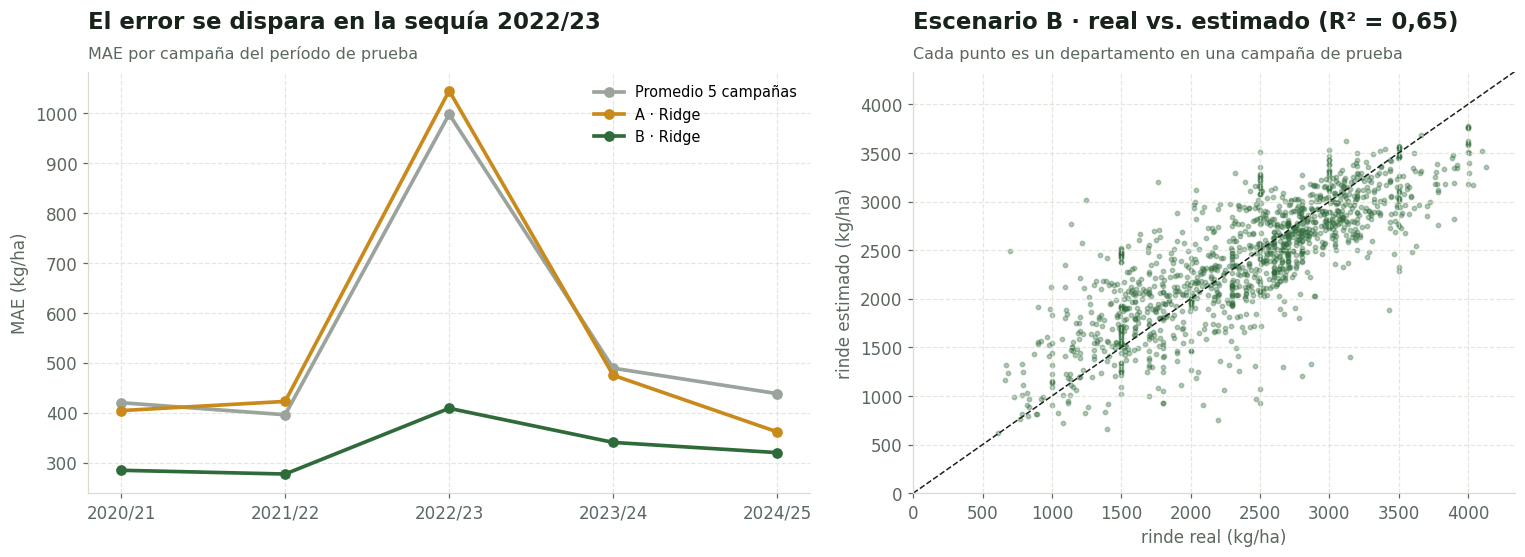

anio,2020,2021,2022,2023,2024
Promedio 5 campañas,"420,00","396,00","998,00","489,00","438,00"
A · Ridge,"404,00","423,00","1.045,00","475,00","361,00"
B · Ridge,"285,00","277,00","409,00","340,00","320,00"


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 5.8  Error por campaña y dispersión real vs. predicho
# ─────────────────────────────────────────────────────────────────────────────
mod_A, mod_B = ganador['A · anticipado']['modelo'], ganador['B · espacial']['modelo']
res_te = te[['anio', 'provincia_id', 'departamento_id', 'superficie_cosechada_ha', OBJETIVO]].copy()
res_te['pred_A'] = predicciones_test[('A · anticipado', mod_A)]
res_te['pred_B'] = predicciones_test[('B · espacial', mod_B)]
res_te['base'] = te['rend_media5'].values

res_te['ae_base'] = (res_te[OBJETIVO] - res_te['base'].fillna(res_te['pred_A'])).abs()
res_te['ae_A'] = (res_te[OBJETIVO] - res_te['pred_A']).abs()
res_te['ae_B'] = (res_te[OBJETIVO] - res_te['pred_B']).abs()
por_anio = res_te.groupby('anio')[['ae_base', 'ae_A', 'ae_B']].mean()
por_anio.columns = ['Promedio 5 campañas', f'A · {mod_A}', f'B · {mod_B}']
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={'width_ratios': [1.2, 1]})
for col, c in zip(por_anio.columns, ['#9AA39C', DORADO, VERDE]):
    a1.plot(por_anio.index, por_anio[col], marker='o', lw=2.4, color=c, label=col)
a1.set_xticks(por_anio.index); a1.set_xticklabels([f'{a}/{str(a + 1)[-2:]}' for a in por_anio.index])
a1.set_ylabel('MAE (kg/ha)'); a1.legend(fontsize=9.5)
titulo(a1, 'El error se dispara en la sequía 2022/23', 'MAE por campaña del período de prueba')

a2.scatter(res_te[OBJETIVO], res_te['pred_B'], s=8, alpha=.35, color=VERDE)
lim = [0, res_te[[OBJETIVO, 'pred_B']].max().max() * 1.05]
a2.plot(lim, lim, color=TINTA, lw=1, ls='--'); a2.set_xlim(lim); a2.set_ylim(lim)
a2.set_xlabel('rinde real (kg/ha)'); a2.set_ylabel('rinde estimado (kg/ha)')
r2b = r2_score(res_te[OBJETIVO], res_te['pred_B'])
titulo(a2, f'Escenario B · real vs. estimado (R² = {miles(r2b, 2)})', 'Cada punto es un departamento en una campaña de prueba')
plt.tight_layout(); plt.show()
display(por_anio.round(0).T)

**Lectura.** En las campañas normales los tres enfoques tienen errores parecidos y moderados. En **2022/23** el pronóstico anticipado (y el promedio histórico) se equivocan por más del doble: nadie podía saber de antemano que llovería tan poco. El escenario B, que "ve" el rinde del resto de la provincia, mantiene el error bajo incluso ese año. La nube de real vs. estimado se alinea con la diagonal, con algo más de dispersión en los rindes muy bajos (lotes casi perdidos).

## 5.9 Interpretación: ¿qué variables usa el modelo?

Se calcula la **importancia por permutación**: se desordena al azar una variable en el conjunto de prueba y se mide cuánto empeora el MAE. Si el error sube mucho, el modelo dependía de esa variable. A diferencia de la importancia interna de los árboles, este método es comparable entre modelos y se mide sobre datos no vistos.

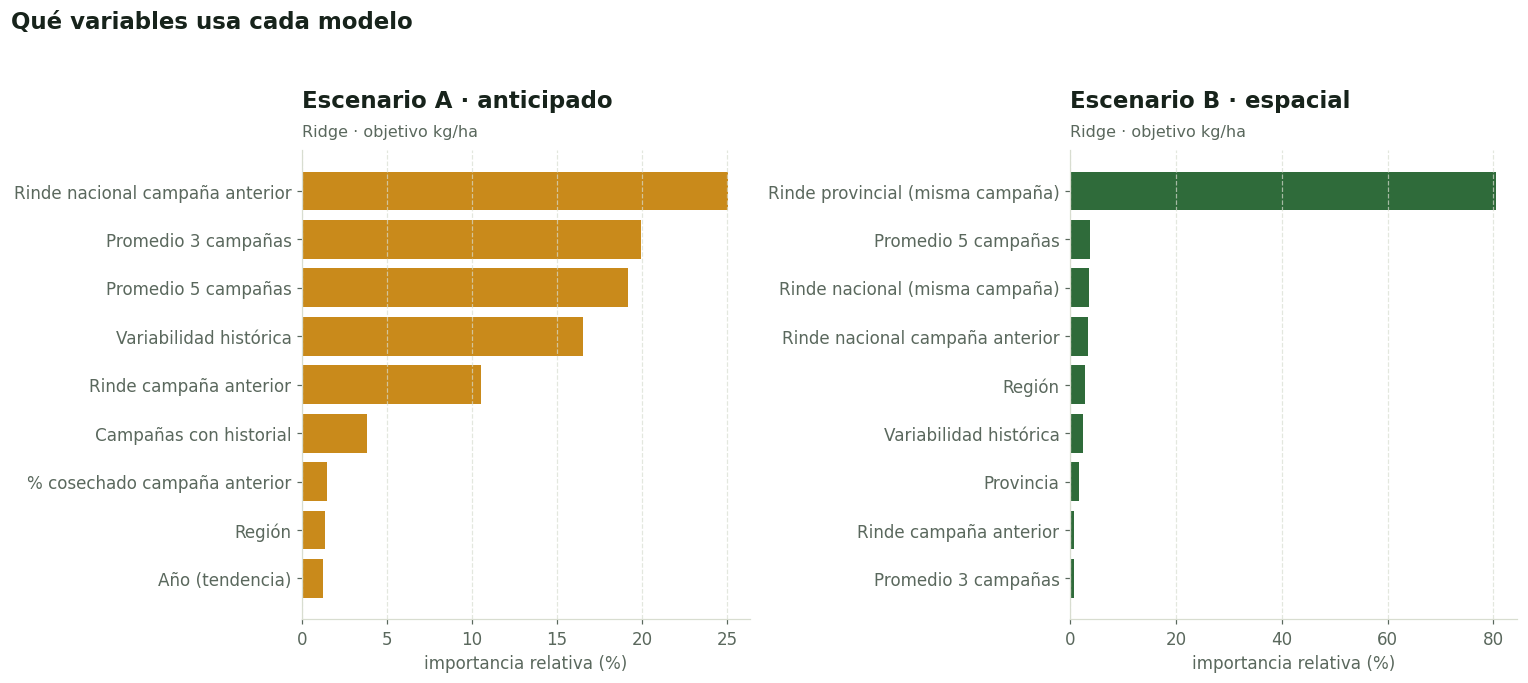

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 5.9  Importancia por permutación (escenarios A y B)
# ─────────────────────────────────────────────────────────────────────────────
ETIQUETAS = {'anio': 'Año (tendencia)', 'rend_lag1': 'Rinde campaña anterior', 'rend_lag2': 'Rinde hace 2 campañas',
             'rend_media3': 'Promedio 3 campañas', 'rend_media5': 'Promedio 5 campañas', 'rend_std5': 'Variabilidad histórica',
             'ratio_cos_lag1': '% cosechado campaña anterior', 'log_sup': 'Superficie sembrada', 'var_sup': 'Cambio de superficie',
             'rend_nac_lag1': 'Rinde nacional campaña anterior', 'n_hist': 'Campañas con historial',
             'rend_prov_loo': 'Rinde provincial (misma campaña)', 'rend_nac_loo': 'Rinde nacional (misma campaña)',
             'anom_prov': 'Anomalía provincial', 'provincia_id': 'Provincia', 'region': 'Región'}

importancias = {}
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, esc in zip(axes, ESCENARIOS):
    g = ganador[esc]; variables = ESCENARIOS[esc]; rel = g['objetivo'] == 'relativo'
    modelo = entrenar(g['modelo'], variables, g['hiperparámetros'], trva, rel)
    Xte = preparar_X(te, variables)
    y_eval = te[OBJETIVO] / base_relativa(te) if rel else te[OBJETIVO]
    pi = permutation_importance(modelo, Xte, y_eval, scoring='neg_mean_absolute_error', n_repeats=5, random_state=SEMILLA, n_jobs=-1)
    imp = pd.Series(pi.importances_mean, index=Xte.columns)
    imp = imp / imp.clip(lower=0).sum() * 100
    importancias[esc] = imp.sort_values(ascending=False)
    s = imp.sort_values().tail(9)
    ax.barh([ETIQUETAS.get(i, i) for i in s.index], s.values, color=VERDE if esc.startswith('B') else DORADO)
    ax.set_xlabel('importancia relativa (%)'); ax.grid(axis='y', visible=False)
    titulo(ax, f'Escenario {esc}', f'{g["modelo"]} · objetivo {g["objetivo"]}')
fig.suptitle('Qué variables usa cada modelo', x=0.01, ha='left', fontsize=15, fontweight='bold', color=TINTA, y=1.03)
plt.tight_layout(); plt.show()

**Lectura.**
- En el **escenario A** pesan el historial reciente del departamento (promedios de 3 y 5 campañas, variabilidad) y el rinde nacional de la campaña anterior: el modelo aprende, esencialmente, "este lugar suele rendir tanto, en el nivel tecnológico actual". El año casi no aporta porque la tendencia ya está contenida en los promedios recientes.
- En el **escenario B** una variable explica casi todo: el **rinde provincial de la misma campaña**. Es la forma en que el clima del año entra al modelo. El historial queda en segundo plano y sirve para calibrar a cada departamento respecto de su provincia.

Esto confirma la hipótesis del capítulo 3: **lo que más explica el rendimiento de una campaña es un factor común del año y de la zona**, que en la práctica es el clima.

## 5.10 Errores por territorio

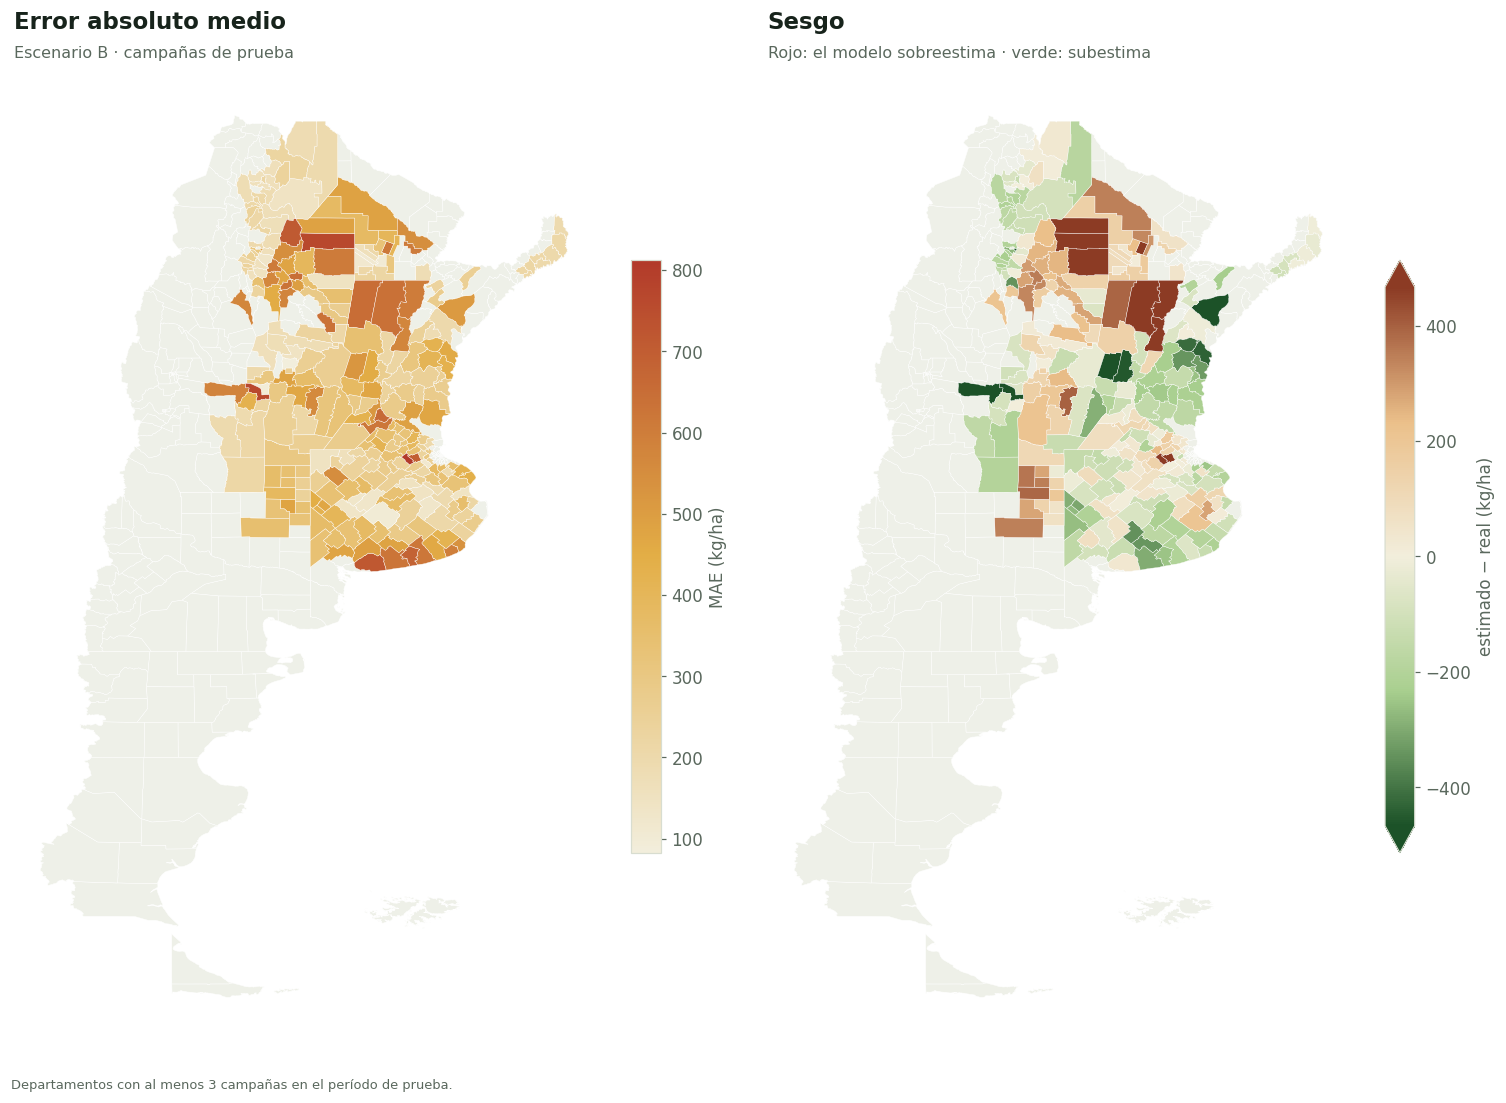

,MAE,sesgo,registros
provincia,,,
Buenos Aires,330,-39,477
Santiago del Estero,482,227,120
Córdoba,272,55,113
Santa Fe,443,43,95
Chaco,316,175,88
Entre Ríos,334,-253,80
Salta,208,-146,71
Tucumán,223,-157,70
La Pampa,340,209,58


In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 5.10  Error medio por departamento (escenario B, período de prueba)
# ─────────────────────────────────────────────────────────────────────────────
res_te['err_B'] = res_te['pred_B'] - res_te[OBJETIVO]
err_dep = res_te.groupby('departamento_id').agg(mae=('err_B', lambda e: e.abs().mean()), sesgo=('err_B', 'mean'),
                                                 n=('err_B', 'size'))
err_dep = err_dep[err_dep['n'] >= 3]
g4 = geo_dep.merge(err_dep, on='departamento_id', how='left')

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 9.5))
mapa(a1, g4, 'mae', cmap=LinearSegmentedColormap.from_list('err', ['#F2EEDC', '#E3AE46', '#B23A2A']), leyenda='MAE (kg/ha)')
titulo(a1, 'Error absoluto medio', 'Escenario B · campañas de prueba')
lim_s = np.nanpercentile(np.abs(g4['sesgo']), 95)
mapa(a2, g4, 'sesgo', cmap=CMAP_DIV.reversed(), leyenda='estimado − real (kg/ha)', vmin=-lim_s, vmax=lim_s)
titulo(a2, 'Sesgo', 'Rojo: el modelo sobreestima · verde: subestima')
fuente(fig, 'Departamentos con al menos 3 campañas en el período de prueba.'); plt.tight_layout(); plt.show()

err_prov = (res_te.groupby('provincia_id').agg(MAE=('err_B', lambda e: e.abs().mean()), sesgo=('err_B', 'mean'), registros=('err_B', 'size'))
            .assign(provincia=lambda x: x.index.map(df.drop_duplicates('provincia_id').set_index('provincia_id')['provincia_nombre']))
            .set_index('provincia').sort_values('registros', ascending=False).head(10))
display(err_prov.style.format('{:,.0f}'))

**Lectura.** El error no sigue un patrón simple de centro y periferia: es mayor en las provincias **internamente heterogéneas**, como Santa Fe (el sur pertenece a la zona núcleo y el norte no) o Santiago del Estero, porque allí el promedio provincial representa mal a departamentos muy distintos entre sí. El sesgo positivo en provincias de frontera agrícola indica que el modelo tiende a sobreestimar en los años malos de esas zonas. Ambas observaciones sugieren una mejora concreta: reemplazar el contexto **provincial** por el de los **departamentos vecinos**.

## 5.11 Generalización a otros cultivos

Se repite el procedimiento completo (construcción de variables, selección del modelo en validación y evaluación en prueba) para **maíz, trigo y girasol**. Para acotar el tiempo de ejecución se compara Ridge (4 niveles de regularización) con Gradient Boosting (2 configuraciones), en ambas versiones de la variable objetivo.

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 5.11  Mismo pipeline para maíz, trigo y girasol
# ─────────────────────────────────────────────────────────────────────────────
CANDIDATOS = ([('Ridge', {'alpha': a}) for a in [10, 100, 300, 1000]] +
              [('Gradient Boosting', {'learning_rate': 0.05, 'max_leaf_nodes': h, 'min_samples_leaf': 40, 'l2_regularization': 1.0})
               for h in [15, 31]])
filas, modelos_cultivo = [], {}
for cult in GRANDES:
    d = construir_dataset(cult)
    d_tr, d_va, d_te = particion(d)
    d_trva = pd.concat([d_tr, d_va])
    fila = {'cultivo': nombre(cult), 'filas': len(d),
            'base A · promedio 5 (MAE)': metricas(d_te[OBJETIVO], d_te['rend_media5'].fillna(d_te['rend_media3']))['MAE'],
            'base B · rinde provincial (MAE)': metricas(d_te[OBJETIVO], d_te['rend_prov_loo'])['MAE']}
    for esc, variables in ESCENARIOS.items():
        cand = []
        for tipo, params in CANDIDATOS:
            for rel in (False, True):
                m = entrenar(tipo, variables, params, d_tr, rel)
                cand.append((metricas(d_va[OBJETIVO], predecir(m, variables, d_va, rel))['MAE'], tipo, params, rel))
        _, tipo, params, rel = min(cand, key=lambda x: x[0])
        m = entrenar(tipo, variables, params, d_trva, rel)
        r = metricas(d_te[OBJETIVO], predecir(m, variables, d_te, rel))
        fila[f'{esc[0]} · modelo'] = tipo
        fila[f'{esc[0]} · MAE'], fila[f'{esc[0]} · R²'], fila[f'{esc[0]} · MAPE %'] = r['MAE'], r['R²'], r['MAPE %']
        modelos_cultivo[(cult, esc)] = (tipo, params, rel)
    filas.append(fila)
gen = pd.DataFrame(filas).set_index('cultivo')
gen['mejora B vs. base B %'] = (1 - gen['B · MAE'] / gen['base B · rinde provincial (MAE)']) * 100
gen['mejora A vs. base A %'] = (1 - gen['A · MAE'] / gen['base A · promedio 5 (MAE)']) * 100
r2b = gen['B · R²']
nota(f'**R² del escenario B en prueba:** ' + ' · '.join(f'{c} {miles(v, 2)}' for c, v in r2b.items()))
cols_num = [c for c in gen.columns if 'modelo' not in c]
display(gen.style.format('{:,.0f}', subset=cols_num).format('{:,.2f}', subset=['A · R²', 'B · R²'])
        .format('{:,.1f}', subset=['A · MAPE %', 'B · MAPE %', 'mejora B vs. base B %', 'mejora A vs. base A %'])
        .background_gradient(cmap=CMAP_AGRO, subset=['B · R²']))

**R² del escenario B en prueba:** Soja 0,65 · Maíz 0,74 · Trigo 0,75 · Girasol 0,58

,filas,base A · promedio 5 (MAE),base B · rinde provincial (MAE),A · modelo,A · MAE,A · R²,A · MAPE %,B · modelo,B · MAE,B · R²,B · MAPE %,mejora B vs. base B %,mejora A vs. base A %
cultivo,,,,,,,,,,,,,
Soja,"10,427",545,347,Ridge,541,0.03,31.5,Ridge,326,0.65,15.9,6.0,0.8
Maíz,"15,485","1,173",807,Ridge,"1,310",0.20,34.0,Ridge,736,0.74,16.7,8.9,-11.7
Trigo,"11,530",583,523,Ridge,627,0.58,35.3,Ridge,473,0.75,23.2,9.5,-7.4
Girasol,"9,556",295,332,Ridge,291,0.49,15.8,Ridge,252,0.58,12.9,24.0,1.4


**Lectura.** El patrón se confirma en los cuatro cultivos:
- El **pronóstico anticipado** no logra superar al promedio histórico del departamento: empata en soja y girasol y queda por detrás en maíz y trigo, cuyas series tienen saltos tecnológicos y climáticos más bruscos.
- La **estimación espacial** mejora a la regla del rinde provincial en todos los cultivos, con R² de entre 0,58 (girasol) y 0,75 (trigo). El girasol tiene el ajuste más bajo porque se cultiva en zonas más dispersas, con menos departamentos por provincia que aporten contexto.
- La regresión Ridge vuelve a ser la elección en casi todos los casos; solo en el maíz con contexto espacial el Gradient Boosting rinde mejor.

## 5.12 Aplicación 1: detección de estimaciones sospechosas

Un buen modelo del escenario B sirve como **auditor automático de la base**: si el rinde informado de un departamento se aleja mucho de lo que indican su historia y su provincia en esa misma campaña, el registro merece una revisión. Para evitar falsas alarmas se exige que el desvío sea extremo **frente al modelo** (z robusto mayor a 3,5, calculado con la mediana de los desvíos absolutos) **y también frente al rinde provincial** (más de un 50 % de diferencia). Esto extiende el capítulo 2 con un control estadístico, no solo de reglas.

Para evaluar **toda** la serie histórica sin que el modelo vea el dato que juzga, se usa **validación cruzada agrupada por campaña**: las campañas se reparten en 5 grupos; cada grupo se predice con un modelo entrenado en los otros cuatro.

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 5.12  Predicción fuera de muestra para toda la serie y alertas de calidad
# ─────────────────────────────────────────────────────────────────────────────
from sklearn.model_selection import GroupKFold
gB = ganador['B · espacial']; relB = gB['objetivo'] == 'relativo'
oof = np.full(len(ds), np.nan)
for idx_tr, idx_te in GroupKFold(n_splits=5).split(ds, groups=ds['anio']):
    m = entrenar(gB['modelo'], VARS_B, gB['hiperparámetros'], ds.iloc[idx_tr], relB)
    oof[idx_te] = predecir(m, VARS_B, ds.iloc[idx_te], relB)

aud = ds[['anio', 'provincia_id', 'departamento_id', 'superficie_cosechada_ha', OBJETIVO, 'rend_prov_loo', 'rend_media5']].copy()
aud['estimado'] = oof
aud['desvio_%'] = (aud[OBJETIVO] / aud['estimado'] - 1) * 100
mad = (aud['desvio_%'] - aud['desvio_%'].median()).abs().median()
aud['z_robusto'] = (aud['desvio_%'] - aud['desvio_%'].median()) / (1.4826 * mad)
# Alerta: el rinde se aparta fuerte del modelo Y también del contexto provincial de esa campaña
aud['desvio_prov_%'] = (aud[OBJETIVO] / aud['rend_prov_loo'] - 1) * 100
alertas = aud[(aud['z_robusto'].abs() > 3.5) & (aud['desvio_prov_%'].abs() > 50)
              & (aud['superficie_cosechada_ha'] >= 1000)].copy()
nombres_dep = df.drop_duplicates('departamento_id').set_index('departamento_id')[['departamento_nombre', 'provincia_nombre']]
alertas = alertas.join(nombres_dep, on='departamento_id').sort_values('z_robusto', key=abs, ascending=False)
alertas['campaña'] = alertas['anio'].map(lambda a: f'{a}/{a + 1}')

print(f'Registros auditados: {miles(len(aud))} · MAE fuera de muestra: {miles(np.nanmean(np.abs(aud[OBJETIVO] - aud["estimado"])))} kg/ha')
print(f'Alertas (desvío extremo respecto del modelo y de la provincia, ≥ 1.000 ha): {len(alertas)} ({miles(len(alertas) / len(aud) * 100, 2)} %)')
display(alertas[['campaña', 'provincia_nombre', 'departamento_nombre', 'superficie_cosechada_ha', OBJETIVO, 'estimado',
                 'rend_prov_loo', 'desvio_%', 'desvio_prov_%', 'z_robusto']].head(12)
        .style.format({'superficie_cosechada_ha': '{:,.0f}', OBJETIVO: '{:,.0f}', 'estimado': '{:,.0f}',
                       'rend_prov_loo': '{:,.0f}', 'desvio_%': '{:+,.0f} %', 'desvio_prov_%': '{:+,.0f} %',
                       'z_robusto': '{:+,.1f}'}).hide(axis='index'))

Registros auditados: 10.427 · MAE fuera de muestra: 285 kg/ha
Alertas (desvío extremo respecto del modelo y de la provincia, ≥ 1.000 ha): 72 (0,69 %)


campaña,provincia_nombre,departamento_nombre,superficie_cosechada_ha,rendimiento_kgxha,estimado,rend_prov_loo,desvio_%,desvio_prov_%,z_robusto
2024/2025,Chaco,Sargento Cabral,"1,050","2,090",920,998,+127 %,+109 %,+8.1
2024/2025,Corrientes,Mercedes,"1,000","2,800","1,238","1,145",+126 %,+145 %,+8.1
2008/2009,Buenos Aires,Tandil,"35,800","2,289","1,026","1,324",+123 %,+73 %,+7.9
2008/2009,Buenos Aires,General Alvarado,"9,500","2,585","1,162","1,329",+122 %,+95 %,+7.8
2022/2023,San Luis,Junín,"4,900","3,147","1,455","1,559",+116 %,+102 %,+7.4
1984/1985,Santiago del Estero,Juan F. Ibarra,"1,600","3,813","1,904","1,910",+100 %,+100 %,+6.4
2009/2010,Corrientes,Sauce,"5,700","2,700","1,388","1,371",+95 %,+97 %,+6.0
1996/1997,Córdoba,Santa María,"123,500","2,474","1,355","1,534",+83 %,+61 %,+5.3
2008/2009,Buenos Aires,Maipú,"15,550",219,"1,118","1,334",-80 %,-84 %,-5.2
2008/2009,Santiago del Estero,Figueroa,"1,300","2,300","1,275","1,284",+80 %,+79 %,+5.1


**Lectura.** Solo una fracción muy pequeña de los registros queda marcada. Al revisarlos aparecen dos tipos de casos: **eventos locales reales** (granizo, inundaciones o sequías que afectaron a un departamento y no a sus vecinos) y **posibles errores de carga** (rindes que no se condicen ni con la historia ni con la zona). Ambos son información valiosa: los primeros para seguros y asistencia, los segundos para la depuración de la fuente.

## 5.13 Aplicación 2: proyección de rendimiento para la campaña 2025/26

Por último, se usa el escenario A para proyectar el rinde de soja de la **próxima campaña** en cada departamento, entrenando con toda la historia disponible. Como un valor puntual sin incertidumbre sería engañoso (sección 5.8), se entrenan además dos modelos de **regresión cuantílica** que estiman los percentiles 10 y 90: el rango dentro del cual debería caer el rinde en 8 de cada 10 campañas.

> **Supuesto.** La superficie sembrada 2025/26 aún no se conoce: se asume igual a la de 2024/25.

Rinde nacional de soja proyectado 2025/2026: 2.758 kg/ha (rango 80 %: 2.291 – 3.106) · real 2024/2025: 2.928 kg/ha


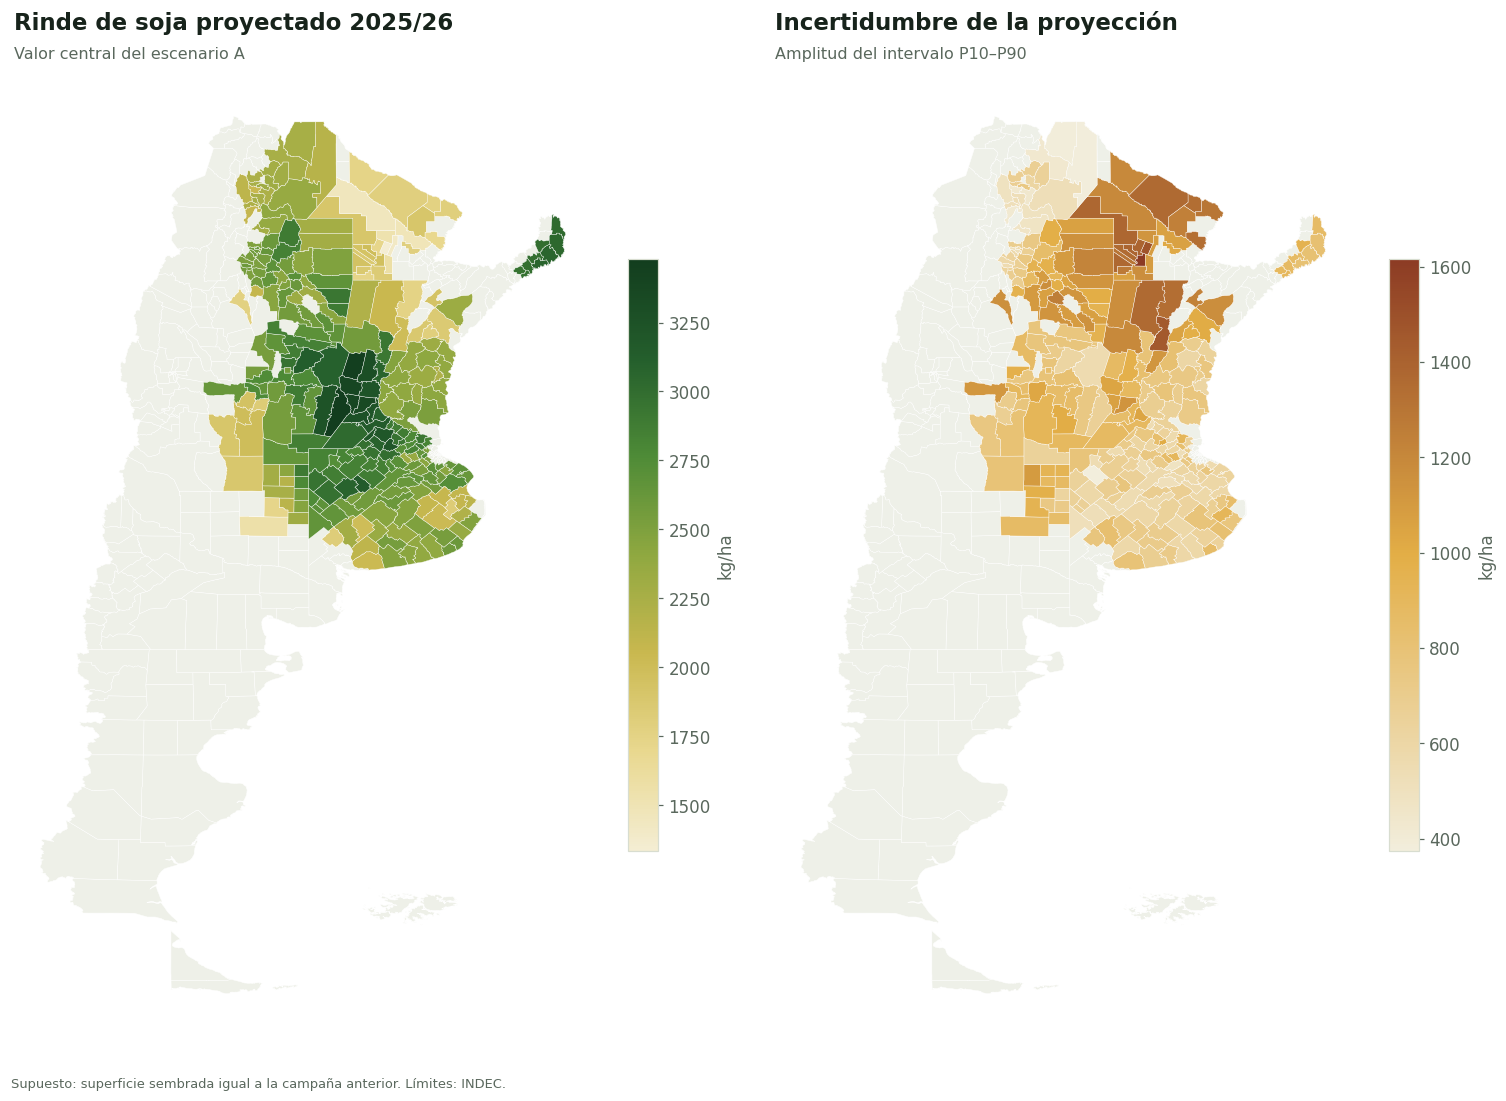

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 5.13  Proyección 2025/26 con intervalos (percentiles 10 y 90)
# ─────────────────────────────────────────────────────────────────────────────
ANIO_PROY = ANIO_MAX + 1
gA = ganador['A · anticipado']

def construir_con_futuro(cultivo):
    hist = construir_dataset(cultivo)
    base = df[(df['cultivo'] == cultivo) & (df['superficie_cosechada_ha'] > 0) & (df['rendimiento_kgxha'] > 0)]
    ultimos = hist[hist['anio'] == ANIO_MAX].set_index('departamento_id')
    serie = base.pivot_table(index='departamento_id', columns='anio', values=OBJETIVO)
    fut = pd.DataFrame(index=ultimos.index)
    fut['anio'] = ANIO_PROY
    fut['provincia_id'] = ultimos['provincia_id']
    fut['region'] = ultimos['region']
    prev = serie.reindex(columns=range(ANIO_MAX - 4, ANIO_MAX + 1)).loc[fut.index]
    fut['rend_lag1'] = prev[ANIO_MAX]
    fut['rend_lag2'] = prev[ANIO_MAX - 1]
    fut['rend_media3'] = prev[[ANIO_MAX - 2, ANIO_MAX - 1, ANIO_MAX]].mean(axis=1)
    fut['rend_media5'] = prev.mean(axis=1)
    fut['rend_std5'] = prev.std(axis=1)
    fut['ratio_cos_lag1'] = ultimos['superficie_cosechada_ha'] / ultimos['superficie_sembrada_ha']
    fut['log_sup'] = np.log1p(ultimos['superficie_sembrada_ha'])
    fut['var_sup'] = 0.0
    fut['rend_nac_lag1'] = serie_rinde(df[df['cultivo'] == cultivo]).loc[ANIO_MAX]
    fut['n_hist'] = ultimos['n_hist'] + 1
    fut['superficie_sembrada_ha'] = ultimos['superficie_sembrada_ha']
    return hist, fut.reset_index()

hist_soja, fut_soja = construir_con_futuro('soja total')
relA = gA['objetivo'] == 'relativo'
modelo_A = entrenar(gA['modelo'], VARS_A, gA['hiperparámetros'], hist_soja, relA)
fut_soja['proyeccion'] = predecir(modelo_A, VARS_A, fut_soja, relA)

XA = preparar_X(hist_soja, VARS_A)
for q in (0.1, 0.9):
    mq = HistGradientBoostingRegressor(loss='quantile', quantile=q, learning_rate=0.05, max_iter=300, max_leaf_nodes=31,
                                       min_samples_leaf=40, categorical_features='from_dtype', random_state=SEMILLA)
    mq.fit(XA, hist_soja[OBJETIVO])
    fut_soja[f'p{int(q * 100)}'] = mq.predict(preparar_X(fut_soja, VARS_A))
fut_soja['p10'] = np.minimum(fut_soja['p10'], fut_soja['proyeccion'])
fut_soja['p90'] = np.maximum(fut_soja['p90'], fut_soja['proyeccion'])

pond = fut_soja['superficie_sembrada_ha']
nac_proy = np.average(fut_soja['proyeccion'], weights=pond)
nac_p10, nac_p90 = np.average(fut_soja['p10'], weights=pond), np.average(fut_soja['p90'], weights=pond)
ult_real = serie_rinde(df[df['cultivo'] == 'soja total']).loc[ANIO_MAX]
print(f'Rinde nacional de soja proyectado {ANIO_PROY}/{ANIO_PROY + 1}: {miles(nac_proy)} kg/ha '
      f'(rango 80 %: {miles(nac_p10)} – {miles(nac_p90)}) · real {ANIO_MAX}/{ANIO_MAX + 1}: {miles(ult_real)} kg/ha')

g5 = geo_dep.merge(fut_soja[['departamento_id', 'proyeccion', 'p10', 'p90']], on='departamento_id', how='left')
g5['amplitud'] = g5['p90'] - g5['p10']
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 9.5))
mapa(a1, g5, 'proyeccion', leyenda='kg/ha')
titulo(a1, f'Rinde de soja proyectado {ANIO_PROY}/{str(ANIO_PROY + 1)[-2:]}', 'Valor central del escenario A')
mapa(a2, g5, 'amplitud', cmap=LinearSegmentedColormap.from_list('inc', ['#F2EEDC', '#E3AE46', '#8C3B24']), leyenda='kg/ha')
titulo(a2, 'Incertidumbre de la proyección', 'Amplitud del intervalo P10–P90')
fuente(fig, 'Supuesto: superficie sembrada igual a la campaña anterior. Límites: INDEC.'); plt.tight_layout(); plt.show()

**Lectura.** La proyección reproduce el mapa estructural del rinde (núcleo pampeano arriba, bordes abajo) y el intervalo es **más ancho donde la historia es más volátil**, típicamente en los márgenes semiáridos. Para planificar, el dato útil no es el valor central sino el rango: indica cuánta producción podría faltar en un año malo.

## 5.14 Exportación de resultados para el tablero BI

Los resultados del capítulo se guardan en archivos que el tablero PHP importa para su sección de predicción:

| Archivo | Contenido |
|:--|:--|
| `modelo_metricas.json` | Configuración ganadora, métricas de validación y prueba, comparación entre cultivos |
| `modelo_predicciones_test.csv` | Rinde real y estimado (escenarios A y B) por departamento en las campañas de prueba |
| `modelo_proyeccion_2025.csv` | Proyección 2025/26 de soja por departamento con intervalo P10–P90 |
| `modelo_importancias.csv` | Importancia por permutación de cada variable |
| `modelo_alertas_calidad.csv` | Registros marcados como sospechosos por el auditor estadístico |

In [ ]:
# ─────────────────────────────────────────────────────────────────────────────
# 5.14  Exportación
# ─────────────────────────────────────────────────────────────────────────────
def limpio(v):
    if isinstance(v, (np.floating, float)): return None if np.isnan(v) else round(float(v), 4)
    if isinstance(v, (np.integer,)): return int(v)
    return v

salida = {
    'cultivo': 'soja total',
    'particion': {'entrenamiento_hasta': FIN_TRAIN, 'validacion_hasta': FIN_VALID, 'prueba_desde': FIN_VALID + 1, 'prueba_hasta': ANIO_MAX},
    'ganadores': {esc: {'modelo': g['modelo'], 'objetivo': g['objetivo'], 'hiperparametros': g['hiperparámetros'],
                        'mae_validacion': limpio(g['MAE'])} for esc, g in ganador.items()},
    'prueba': [{'escenario': e, 'modelo': m, **{k.replace(' %', '').replace('²', '2'): limpio(v) for k, v in r.items()}}
               for (e, m), r in finales.iterrows()],
    'por_campania': {str(a): {k: limpio(v) for k, v in r.items()} for a, r in por_anio.iterrows()},
    'cultivos': [{'cultivo': c, **{k: limpio(v) for k, v in r.items()}} for c, r in gen.iterrows()],
    'proyeccion_nacional': {'campania': f'{ANIO_PROY}/{ANIO_PROY + 1}', 'rinde': limpio(nac_proy), 'p10': limpio(nac_p10),
                            'p90': limpio(nac_p90), 'rinde_ultima_campania': limpio(ult_real)},
}
with open('modelo_metricas.json', 'w', encoding='utf-8') as f:
    json.dump(salida, f, ensure_ascii=False, indent=2, default=lambda o: o.item() if hasattr(o, 'item') else str(o))

res_te.assign(cultivo='soja total').rename(columns={OBJETIVO: 'real', 'pred_A': 'estimado_A', 'pred_B': 'estimado_B', 'base': 'promedio_5'}) \
      .drop(columns=['err_B', 'ae_base', 'ae_A', 'ae_B']).to_csv('modelo_predicciones_test.csv', index=False)
fut_soja.assign(cultivo='soja total', campania=f'{ANIO_PROY}/{ANIO_PROY + 1}')[
    ['cultivo', 'campania', 'provincia_id', 'departamento_id', 'proyeccion', 'p10', 'p90', 'rend_lag1', 'rend_media5']
].to_csv('modelo_proyeccion_2025.csv', index=False)
pd.DataFrame(importancias).rename_axis('variable').reset_index().assign(etiqueta=lambda x: x['variable'].map(ETIQUETAS)) \
  .to_csv('modelo_importancias.csv', index=False)
alertas[['campaña', 'anio', 'provincia_id', 'provincia_nombre', 'departamento_id', 'departamento_nombre', OBJETIVO,
         'estimado', 'desvio_%', 'z_robusto']].to_csv('modelo_alertas_calidad.csv', index=False)

archivos = ['modelo_metricas.json', 'modelo_predicciones_test.csv', 'modelo_proyeccion_2025.csv',
            'modelo_importancias.csv', 'modelo_alertas_calidad.csv', ARCHIVO_LIMPIO]
for a in archivos:
    print(f'  {a:38s} {os.path.getsize(a) / 1024:>9,.0f} KB')

# En Colab: descarga todos los archivos en un .zip para subirlos al tablero
try:
    from google.colab import files
    import zipfile
    with zipfile.ZipFile('resultados_tpi.zip', 'w', zipfile.ZIP_DEFLATED) as z:
        for a in archivos:
            z.write(a)
    print('\nPara descargarlos: ejecutá  files.download("resultados_tpi.zip")')
except ImportError:
    pass

  modelo_metricas.json                           5 KB
  modelo_predicciones_test.csv                 111 KB
  modelo_proyeccion_2025.csv                    27 KB
  modelo_importancias.csv                        1 KB
  modelo_alertas_calidad.csv                     8 KB
  ESTIMACIONES_AGRICOLAS_LIMPIA_EDA.csv     22,505 KB

Para descargarlos: ejecutá  files.download("resultados_tpi.zip")


## 5.15 Conclusiones del capítulo 5

1. **El rendimiento de una campaña no se puede anticipar con precisión solo con su historia.** Los modelos del escenario A empatan con el promedio de las últimas campañas. La razón es el clima: el período de prueba incluye la sequía 2022/23, y ese tipo de evento no está en el dataset.
2. **Con el contexto de la campaña, el problema se vuelve predecible.** El escenario B reduce el error cerca de un 40 % frente al escenario A y supera a la regla "usar el rinde provincial", con R² de entre 0,6 y 0,75 en soja, maíz y trigo.
3. **Más simple fue mejor, y las variables importan más que el algoritmo.** La regresión Ridge le ganó a Random Forest y a Gradient Boosting en validación y en prueba. La diferencia grande no la hizo el algoritmo sino incorporar la información correcta (el contexto de la campaña): **mejores datos le ganan a mejores algoritmos**.
4. **El modelo tiene usos concretos:** auditar la base (sección 5.12), completar estimaciones y proyectar rangos de rinde para planificación (sección 5.13).

**Limitaciones.**
- No hay variables climáticas, de suelo ni de manejo; el modelo las aproxima a través del contexto provincial.
- Los departamentos con poca historia (frontera agrícola reciente) tienen menos información y más error.
- La proyección 2025/26 supone superficie constante y no anticipa eventos climáticos extremos.

**Próximos pasos.** Incorporar precipitación y temperatura del período crítico de cada cultivo (por ejemplo, datos satelitales o reanálisis climáticos por departamento), índices de vegetación satelitales y precios relativos al momento de la siembra.

# Conclusiones generales del trabajo

**Sobre los datos.** La base oficial de estimaciones agrícolas es extensa y de buena calidad, pero no está lista para usar: tiene errores de escala, inconsistencias puntuales y, sobre todo, categorías superpuestas que **inflaban la producción** si se sumaban sin cuidado. El pipeline del capítulo 2 resolvió estos problemas dejando trazabilidad completa.

**Sobre el sector.** La producción agrícola argentina creció de forma sostenida durante medio siglo, impulsada por la soja y el maíz y por un fuerte aumento de la productividad. Está muy concentrada en pocos cultivos y en la región pampeana, y es vulnerable a shocks climáticos que golpean a varios cultivos a la vez.

**Sobre la predicción.** Anticipar el rinde con meses de antelación tiene un límite claro sin datos climáticos; estimarlo con el contexto de la campaña funciona bien y tiene aplicaciones directas en control de calidad y planificación.

**Sobre el proceso.** El trabajo recorrió el ciclo completo de un proyecto de datos: definición del problema, limpieza trazable, exploración, visualización, modelado con validación honesta y comunicación de resultados. Los productos (dataset limpio, métricas y proyecciones) alimentan un tablero interactivo que permite a cualquier usuario explorar los datos sin escribir código.